# Supporting native-export analysis · preserved earlier report

This saved report describes the initial eight-file intake. The user subsequently selected the former app’s twelve completed sections and supplied their expanded exports. Current scientific requirements, resolved cohort/alignment assets and exact remaining blockers are in **TDP43_COMET_analysis.ipynb** and **docs/scientist_questions.md**. Earlier missing-transform/assignment statements below reflect the earlier intake and are superseded. Open `outputs/app/native_explorer.html` for this supporting viewer.


# TDP43 COMET: spatial evidence and scientific review

This report reconstructs **where the supplied detections lie**, compares measurements across overlapping exports, audits morphology and carries forward verified findings from the former PLA–ChAT project. Spatial maps, channel layers, shared scales, source-coordinate review and per-figure explanations now lead the report.

The current native reconstructions use bounding-box midpoints, not microscope pixels or accepted anatomical centroids. The former study's animal-level results remain explicitly historical. The requested aligned **Running − Homecage** count maps still require their existing masks, numerical transforms and current sample relationships. Those limits do not prevent useful spatial and measurement analysis of the supplied exports.

Open `outputs/app/index.html` for linked native maps/overlays, bin and layer controls, a 3D measurement view, paired-export review, object/bin inspection and historical figures. The app is an offline snapshot; its controls do not rerun the raw analysis.

In [1]:
from pathlib import Path
import hashlib, json, os, platform, sys
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'tmp/matplotlib'))
from IPython.display import display, Image, Markdown
import pandas as pd
import numpy as np
manifest = json.loads((ROOT/'metadata/input_manifest.json').read_text())
summary = json.loads((ROOT/'outputs/inventory/summary.json').read_text())
audit = json.loads((ROOT/'outputs/inventory/file_audit.json').read_text())
def file_hash(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):
            h.update(block)
    return h.hexdigest()
integrity=[]
for m in manifest:
    p=Path(m['source_path'])
    if not p.exists():
        p=ROOT/'Initial Data'/m['relative_path']
    integrity.append({'file_id':m['file_id'],'available':p.is_file(),'sha256_matches':p.is_file() and file_hash(p)==m['sha256']})
assert all(r['sha256_matches'] for r in integrity), 'Missing/changed raw inputs; resolve before analysis.'
from comet_spatial.native_atlas import build as build_native_atlas
atlas = build_native_atlas(ROOT, figures=True)
from scripts.build_findings import build as build_findings
facts=build_findings(ROOT)
from scripts.build_report import build as build_report
build_report()
print('Full native recomputation:',len(atlas['exports']),'exports;',summary['total_exported_rows_including_possible_repeats'],'rows; all eight SHA-256 checks pass.')
print('Saved raw-count maps use all detections. Display point samples do not determine summaries.')

Reconstructed input_001: 186,343 rows


Reconstructed input_002: 297,584 rows


Reconstructed input_003: 238,084 rows


Reconstructed input_004: 356,745 rows


Reconstructed input_005: 184,684 rows


Reconstructed input_006: 295,677 rows


Reconstructed input_007: 237,144 rows


Reconstructed input_008: 349,776 rows


{
  "schema_version": "1.0",
  "all_export_rows_reconciled_to_inventory": true,
  "all_grids_count_conserved": true,
  "inputs_opened_read_only": true,
  "raw_hashes": "Reused full SHA-256 inventory records; this run checked sizes and row counts without redundant input rehash.",
  "tissue_masks_generated": false,
  "transforms_fitted": false,
  "conditions_assigned": false,
  "biological_comparisons_performed": false,
  "all_morphology_exclusions_retained_in_counts": true,
  "morphology_review_selected_from_full_exports": true,
  "morphology_review_selection_records": 64,
  "payload_bytes": 11978754
}


Full native recomputation: 8 exports; 2146037 rows; all eight SHA-256 checks pass.
Saved raw-count maps use all detections. Display point samples do not determine summaries.


## What the current exports show

These are **descriptive export-level findings**, not animal-level treatment effects. Four strongly overlapping file pairs remain separate; counts are never summed as independent sections.

The following findings are calculated from the actual CSV rows. The association flag is the exported ChAT-present value on PLA objects; it does not establish neuron identity or physical molecular binding.

In [2]:
display(Markdown(f'''- **Spatial structure:** eight unsmoothed native count reconstructions and channel overlays are now available at three recorded bin widths.
- **ChAT flag among PLA:** {facts['association_flag_percent_range'][0]:.2f}%–{facts['association_flag_percent_range'][1]:.2f}% across exports, each using all PLA in its own denominator.
- **Alternative-export sensitivity:** four overlapping pairs differ by {facts['pla_count_relative_change_percent_range'][0]:+.2f}% to {facts['pla_count_relative_change_percent_range'][1]:+.2f}% in PLA count; flag fractions change {facts['association_change_percentage_point_range'][0]:+.2f} to {facts['association_change_percentage_point_range'][1]:+.2f} percentage points in the specified right-minus-left direction.
- **Morphology review:** {facts['unusable_diameter_ratio_pla_including_repeats']:,} PLA rows have unusable diameter ratios, including repeats; all remain in counts and association summaries.
- **Actionable image review:** {len(atlas['review_targets'])} bin-window selection records target high counts and supported association extremes; {len(atlas['morphology_object_review_targets'])} full-source object records target invalid/zero diameters and area extremes. Selections can overlap across reasons; these are not unique-object or prevalence counts.'''))

- **Spatial structure:** eight unsmoothed native count reconstructions and channel overlays are now available at three recorded bin widths.
- **ChAT flag among PLA:** 42.44%–70.74% across exports, each using all PLA in its own denominator.
- **Alternative-export sensitivity:** four overlapping pairs differ by -7.68% to -1.95% in PLA count; flag fractions change -0.88 to +1.83 percentage points in the specified right-minus-left direction.
- **Morphology review:** 21,964 PLA rows have unusable diameter ratios, including repeats; all remain in counts and association summaries.
- **Actionable image review:** 88 bin-window selection records target high counts and supported association extremes; 64 full-source object records target invalid/zero diameters and area extremes. Selections can overlap across reasons; these are not unique-object or prevalence counts.

## 1. Where are the PLA detections?

**Question:** where does the raw export contain more PLA detections per native bin?

**How to read:** each panel is one export in its own original coordinate frame. Count every PLA bounding-box midpoint once. The shared logarithmic **color display** helps reveal sparse and dense regions; the saved matrices remain raw counts. Bin width is 128 unverified export units in this static figure; the viewer offers 64/128/256. These are new recorded exploratory resolutions, not assumed physical calibration or inherited scientific thresholds.

**Evidence and limit:** repeated spatial patterns are visible in candidate overlapping exports. Pale zero-count bins say only that no exported midpoint fell there; they are not confirmed empty tissue. No outline, anatomy, registration, missing data or original pixel image is invented.

**Next:** inspect bins in the viewer and use the native source windows to review image channels, segmentation and export scope.

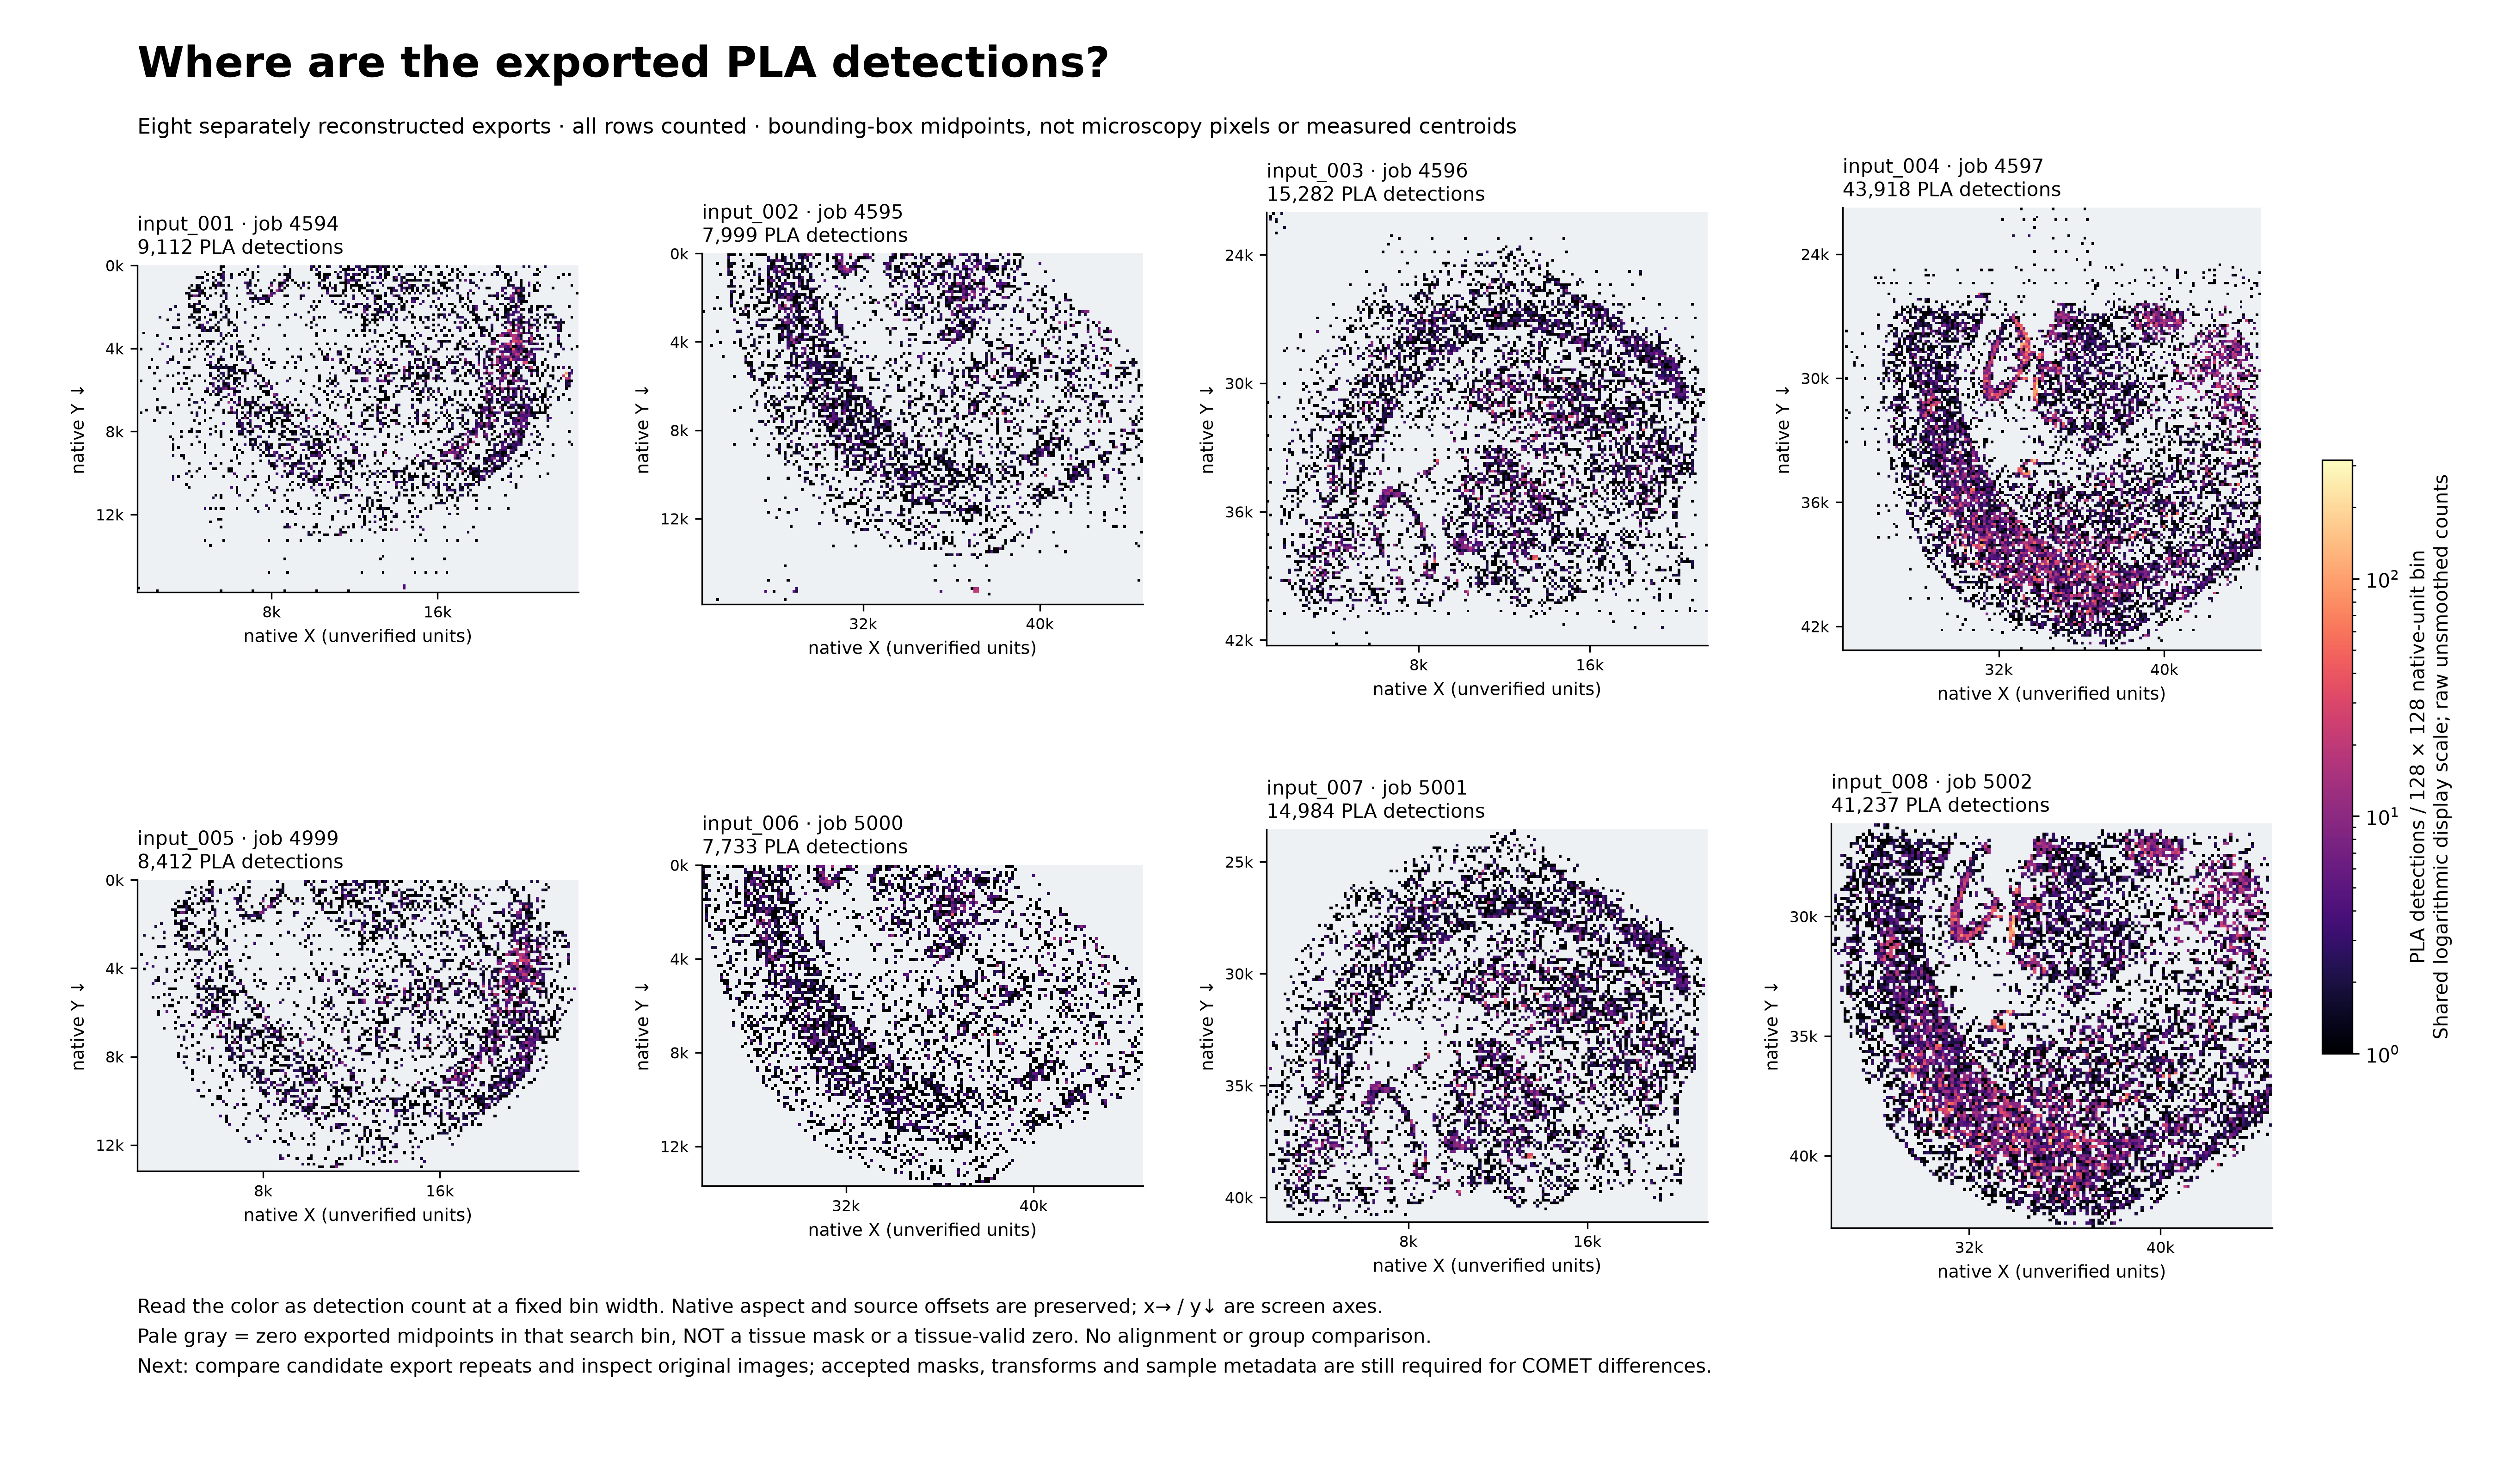

In [3]:
display(Image(filename=str(ROOT/'outputs/native_atlas/figures/native_pla_count_atlas.png'),width=1250))

## 2. How do PLA and ChAT detections occupy the source fields?

**How to read:** gray marks are sampled ChAT-labelled detections; PLA markers distinguish the literal exported ChAT-presence flag. Every marker is a reconstructed midpoint. The app lets you toggle layers, inspect object IDs and boxes, and compare a selected native bin against the full raw-count map.

The display is balanced by class so the much larger ChAT class does not hide PLA. It is not a prevalence sample: total counts, fractions, histograms and review-window counts use all relevant rows. Spatial overlap of reconstructed points is not molecular colocalization, tissue coverage or cell identity. No image-space correspondence across different specimens is implied.

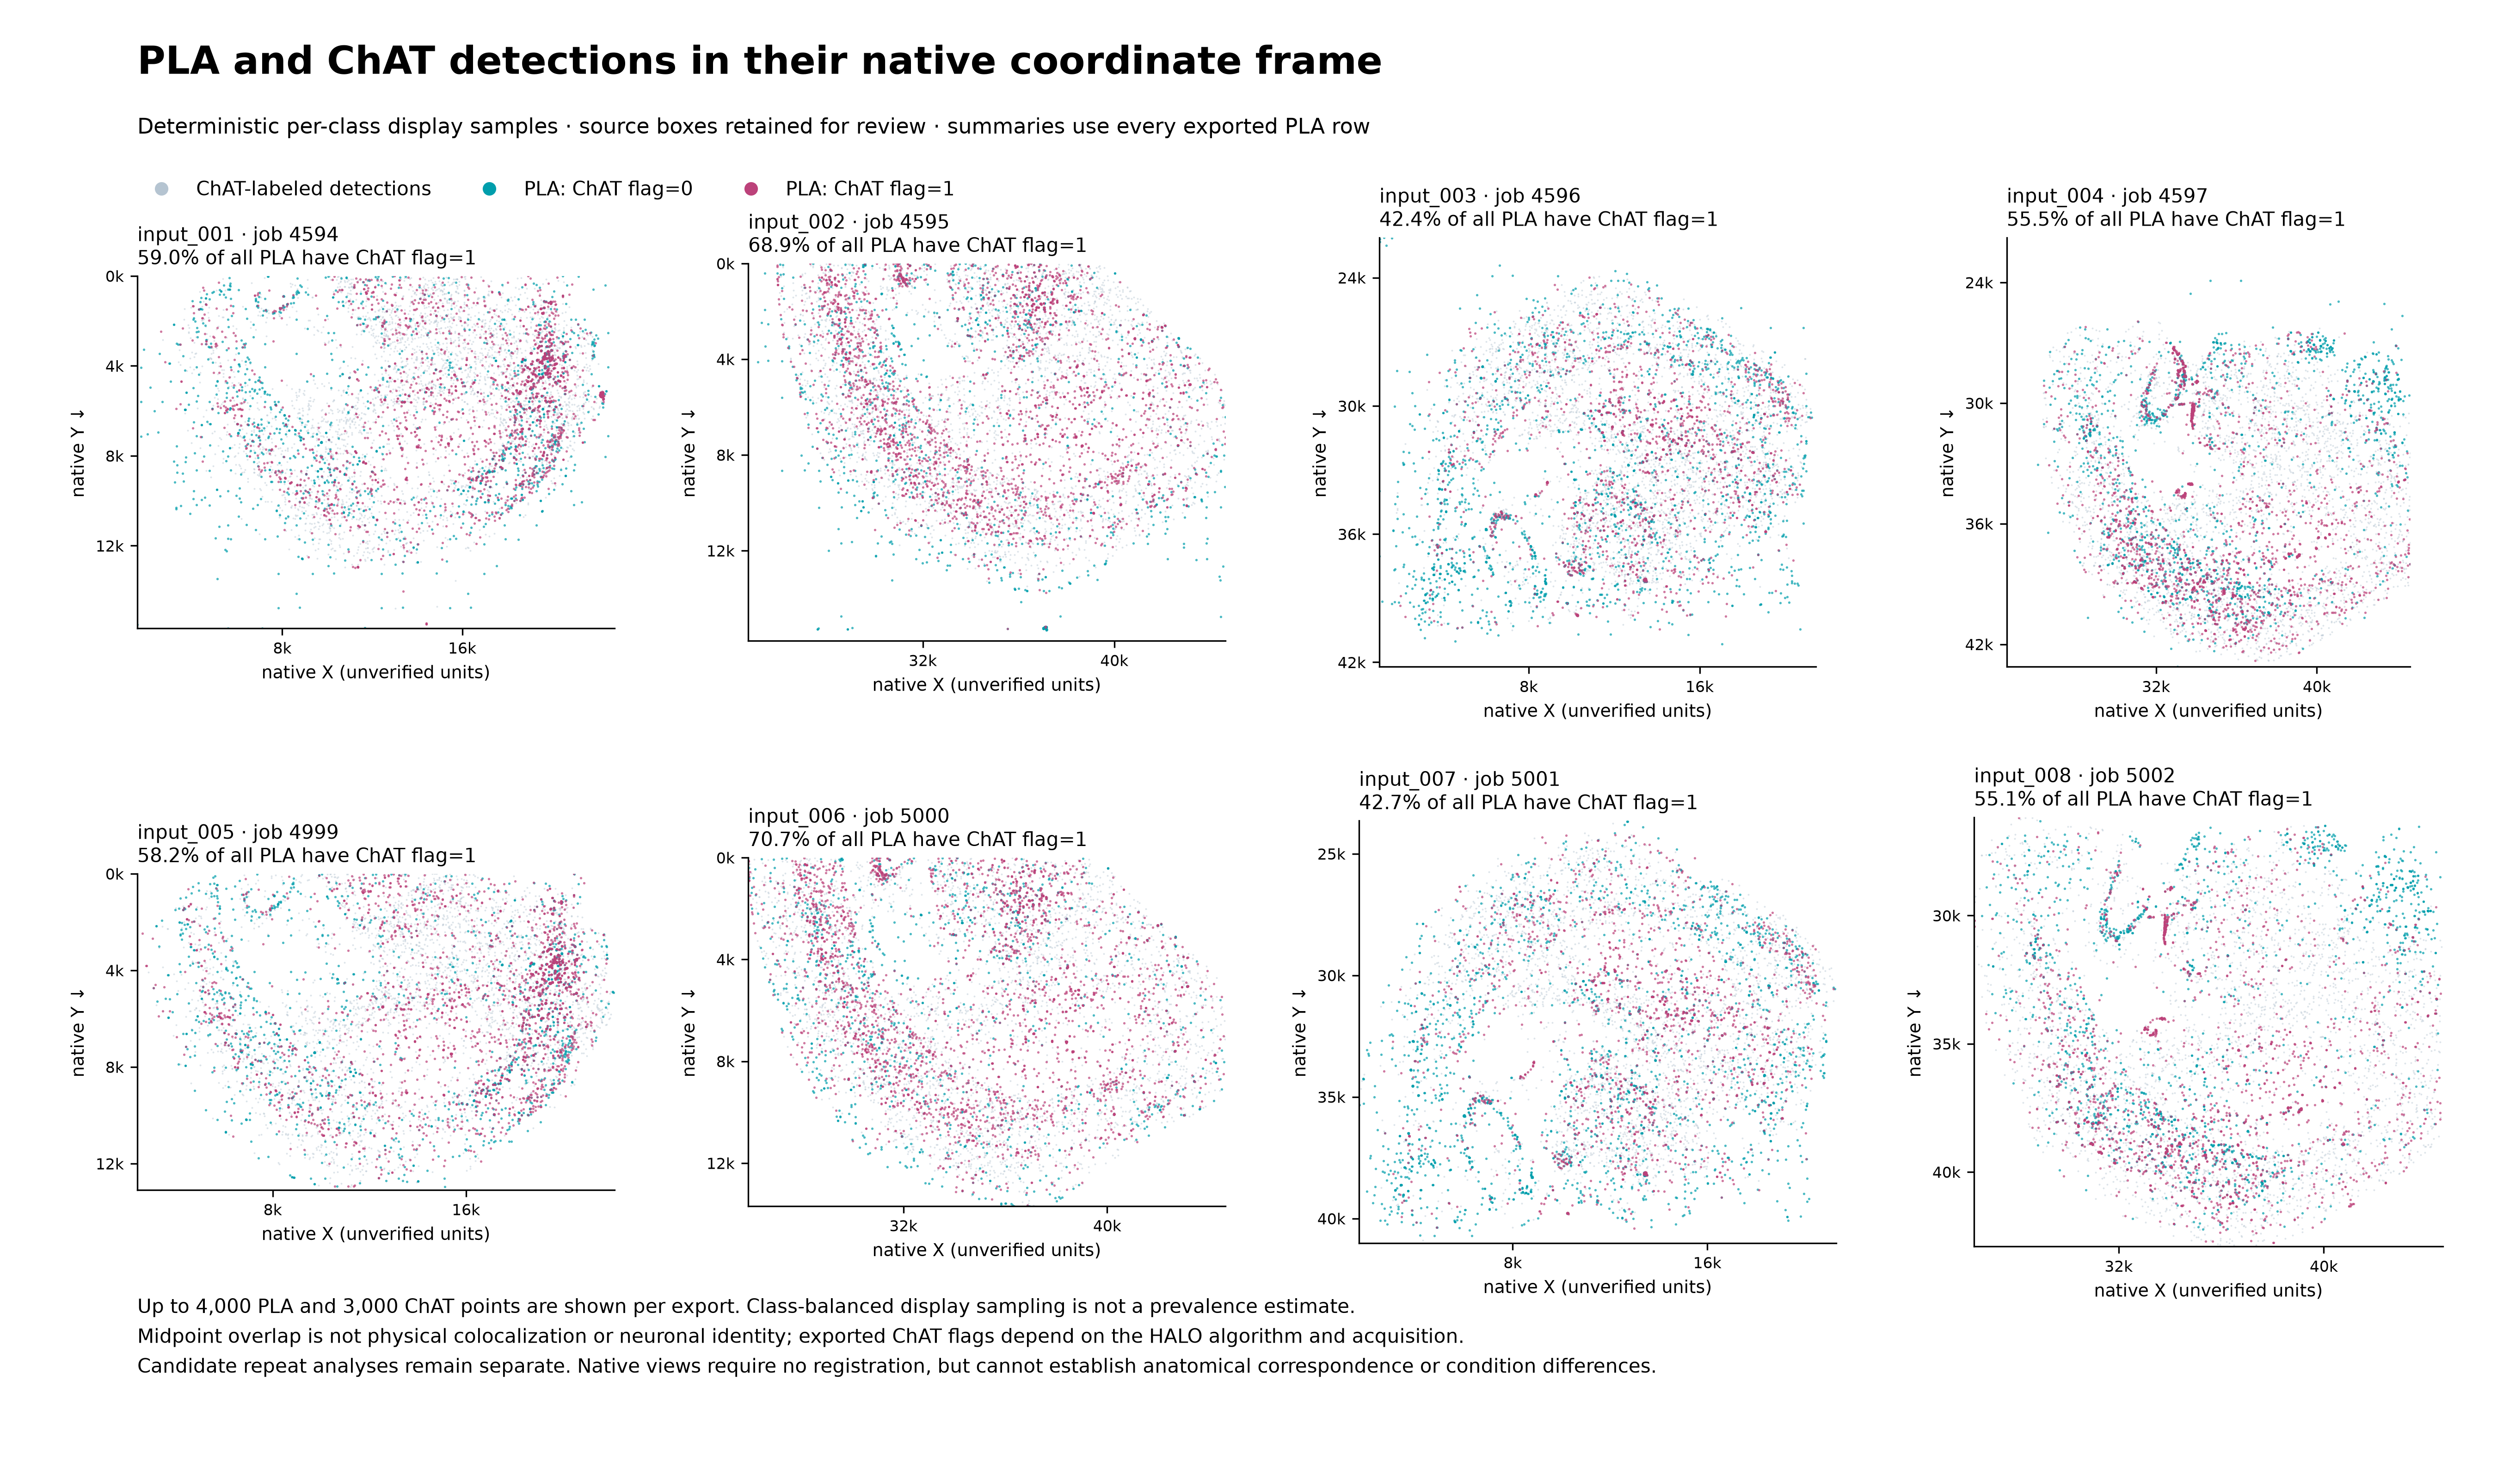

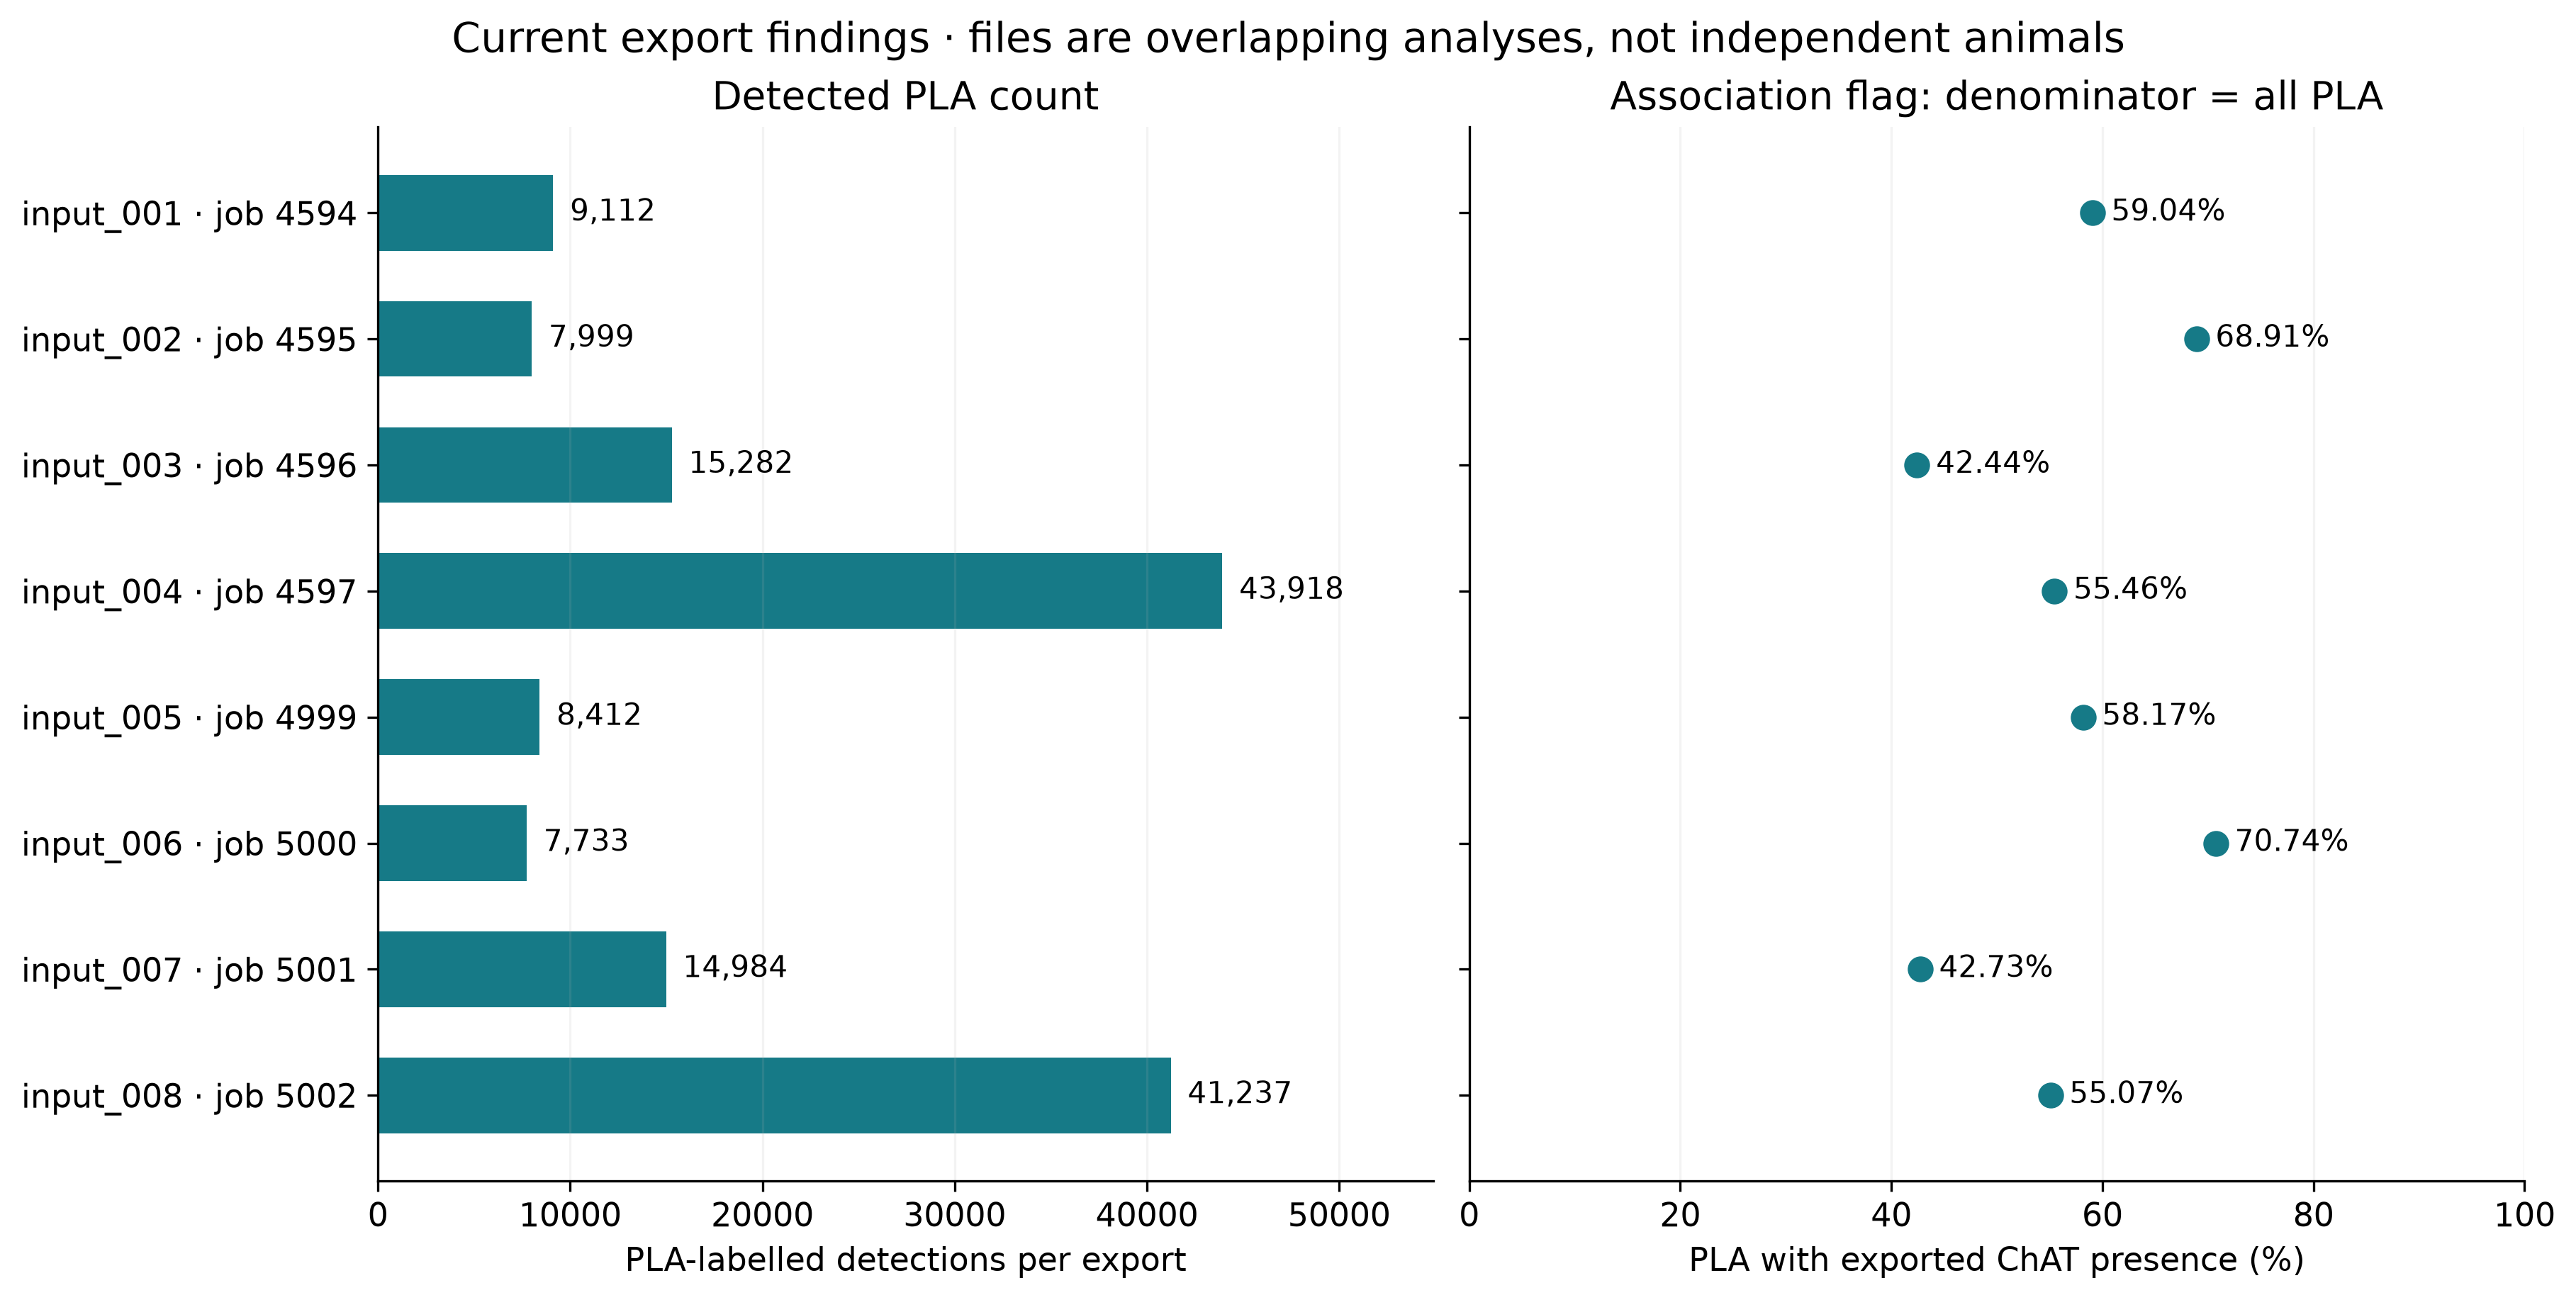

,file_id,job_token,exported_region_label,pla_count,pla_with_chat_flag,pla_chat_flag_percent
0,input_001,4594,22M_Pfkp-TDP43 PLA,9112,5380,59.043020
1,input_002,4595,24M_Pfkp-TDP43 PLA,7999,5512,68.908614
2,input_003,4596,22M_Hk1-TDP43 PLA,15282,6485,42.435545
3,input_004,4597,24M_Hk1-TDP43 PLA,43918,24355,55.455622
4,input_005,4999,22M_TDP43-Pfkp_tight,8412,4893,58.166904
5,input_006,5000,24M_TDP43-Pfkp_tight,7733,5470,70.735808
6,input_007,5001,22M_TDP43-Hk1_tight,14984,6402,42.725574
7,input_008,5002,24M_TDP43-Hk1_tight,41237,22710,55.071901


In [4]:
display(Image(filename=str(ROOT/'outputs/native_atlas/figures/native_layer_overlay_atlas.png'),width=1250))
display(Image(filename=str(ROOT/'outputs/native_atlas/figures/export_signal_profiles.png'),width=1100))
signal_table=pd.read_csv(ROOT/'outputs/native_atlas/export_findings.csv')
display(signal_table[['file_id','job_token','exported_region_label','pla_count','pla_with_chat_flag','pla_chat_flag_percent']])

## 3. Do alternative exports change the measured outcome?

**Question:** do strongly overlapping exports yield exactly the same PLA count and ChAT-presence fraction?

**How to read:** each row compares a pair selected by its high agreement in exported measurements. The left panel changes PLA count relative to the left export; the right panel changes the ChAT-presence fraction in **percentage points**. The plots label their different denominators explicitly. They are comparisons of exported measurements, not condition contrasts or independent replications.

**Evidence:** these outputs differ even though many measurements match. **Uncertainty:** a shared signature does not prove biological object identity or resolve whether the exports are ROI alternatives or reruns. **Next:** compare the linked native maps and record the intended source/inclusion decision before section-level averaging. Do not choose a primary export on the basis of a preferred biological result.

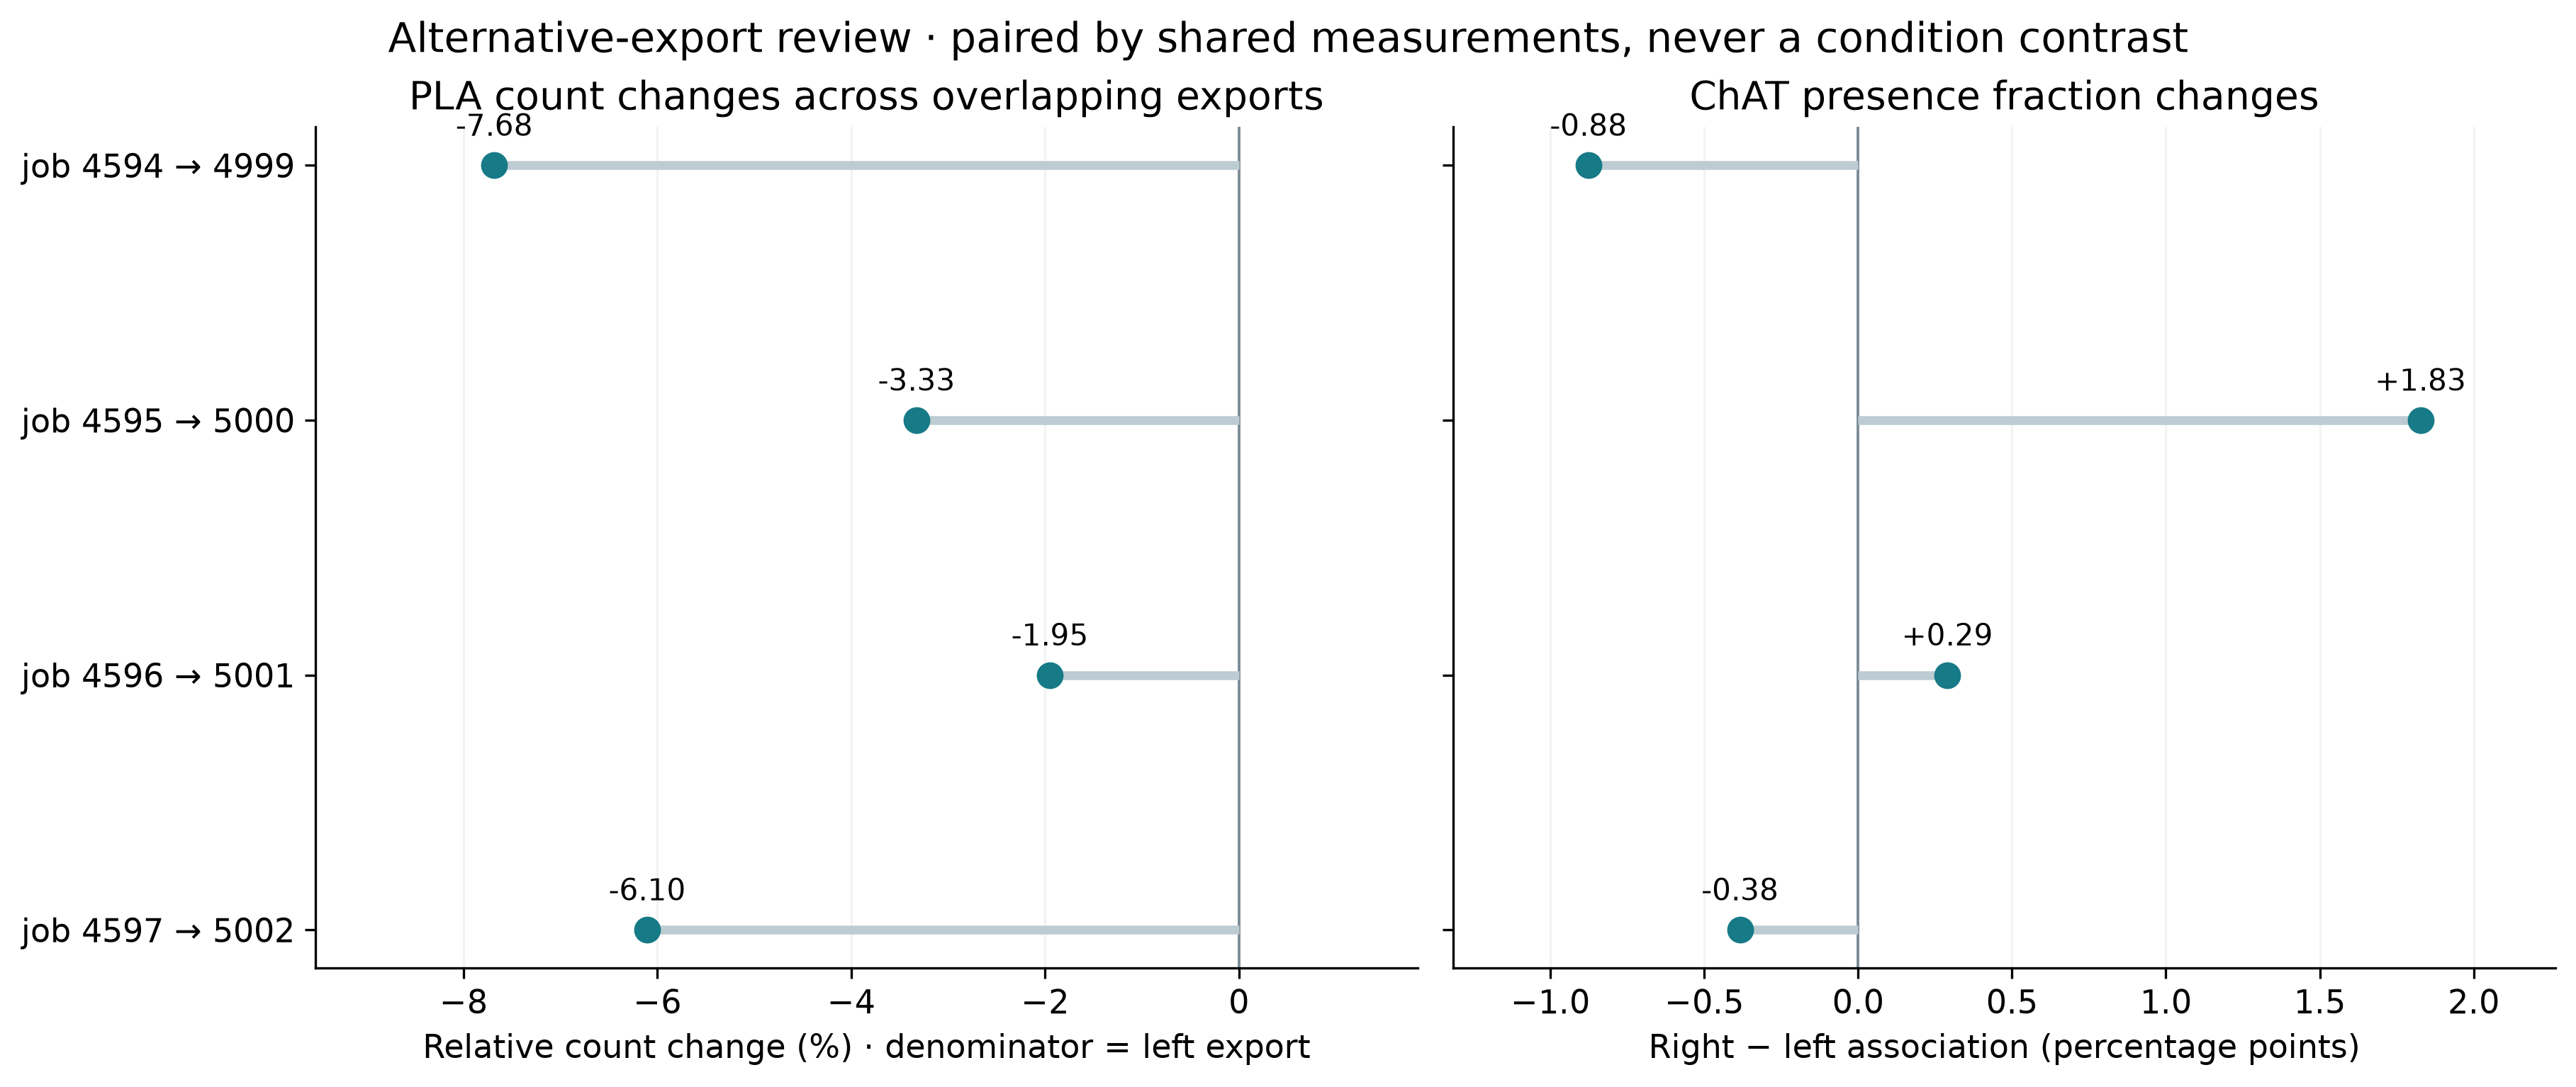

,left_file_id,right_file_id,left_job_token,right_job_token,left_pla,right_pla,right_minus_left_pla_count,pla_count_relative_change_percent,left_chat_flag_percent,right_chat_flag_percent,right_minus_left_association_percentage_points,left_distinct_measurements_shared_percent,right_distinct_measurements_shared_percent,interpretation
0,input_001,input_005,4594,4999,9112,8412,-700,-7.682177,59.043020,58.166904,-0.876116,90.881868,91.698252,Pair selected by measurement agreement; sectio...
1,input_002,input_006,4595,5000,7999,7733,-266,-3.325416,68.908614,70.735808,1.827194,90.587836,91.172094,Pair selected by measurement agreement; sectio...
2,input_003,input_007,4596,5001,15282,14984,-298,-1.950007,42.435545,42.725574,0.290029,91.592428,91.955487,Pair selected by measurement agreement; sectio...
3,input_004,input_008,4597,5002,43918,41237,-2681,-6.104558,55.455622,55.071901,-0.383720,92.995798,94.848945,Pair selected by measurement agreement; sectio...


In [5]:
display(Image(filename=str(ROOT/'outputs/native_atlas/figures/overlapping_export_sensitivity.png'),width=1100))
display(pd.read_csv(ROOT/'outputs/native_atlas/overlapping_export_sensitivity.csv'))

## 4. Which morphology measurements deserve review?

**How to read:** dots are PLA area medians, thick intervals the interquartile range and thin intervals the 1st–99th percentiles. These are object distributions, not animal uncertainty or confidence intervals. The x axis is logarithmic; its area units are literal HALO header units with unverified calibration. The right panel reports the fraction/count lacking a usable **minimum / maximum diameter** ratio.

A zero minimum with a positive maximum is retained as a valid ratio of zero. A nonpositive maximum or invalid/nonfinite diameter pair is excluded only from that ratio. Those objects remain in every raw-count and ChAT-presence summary. **Next:** inspect questionable sizes/diameters in source images before interpreting morphology or fitting any model. No clustering has been added to these current data.

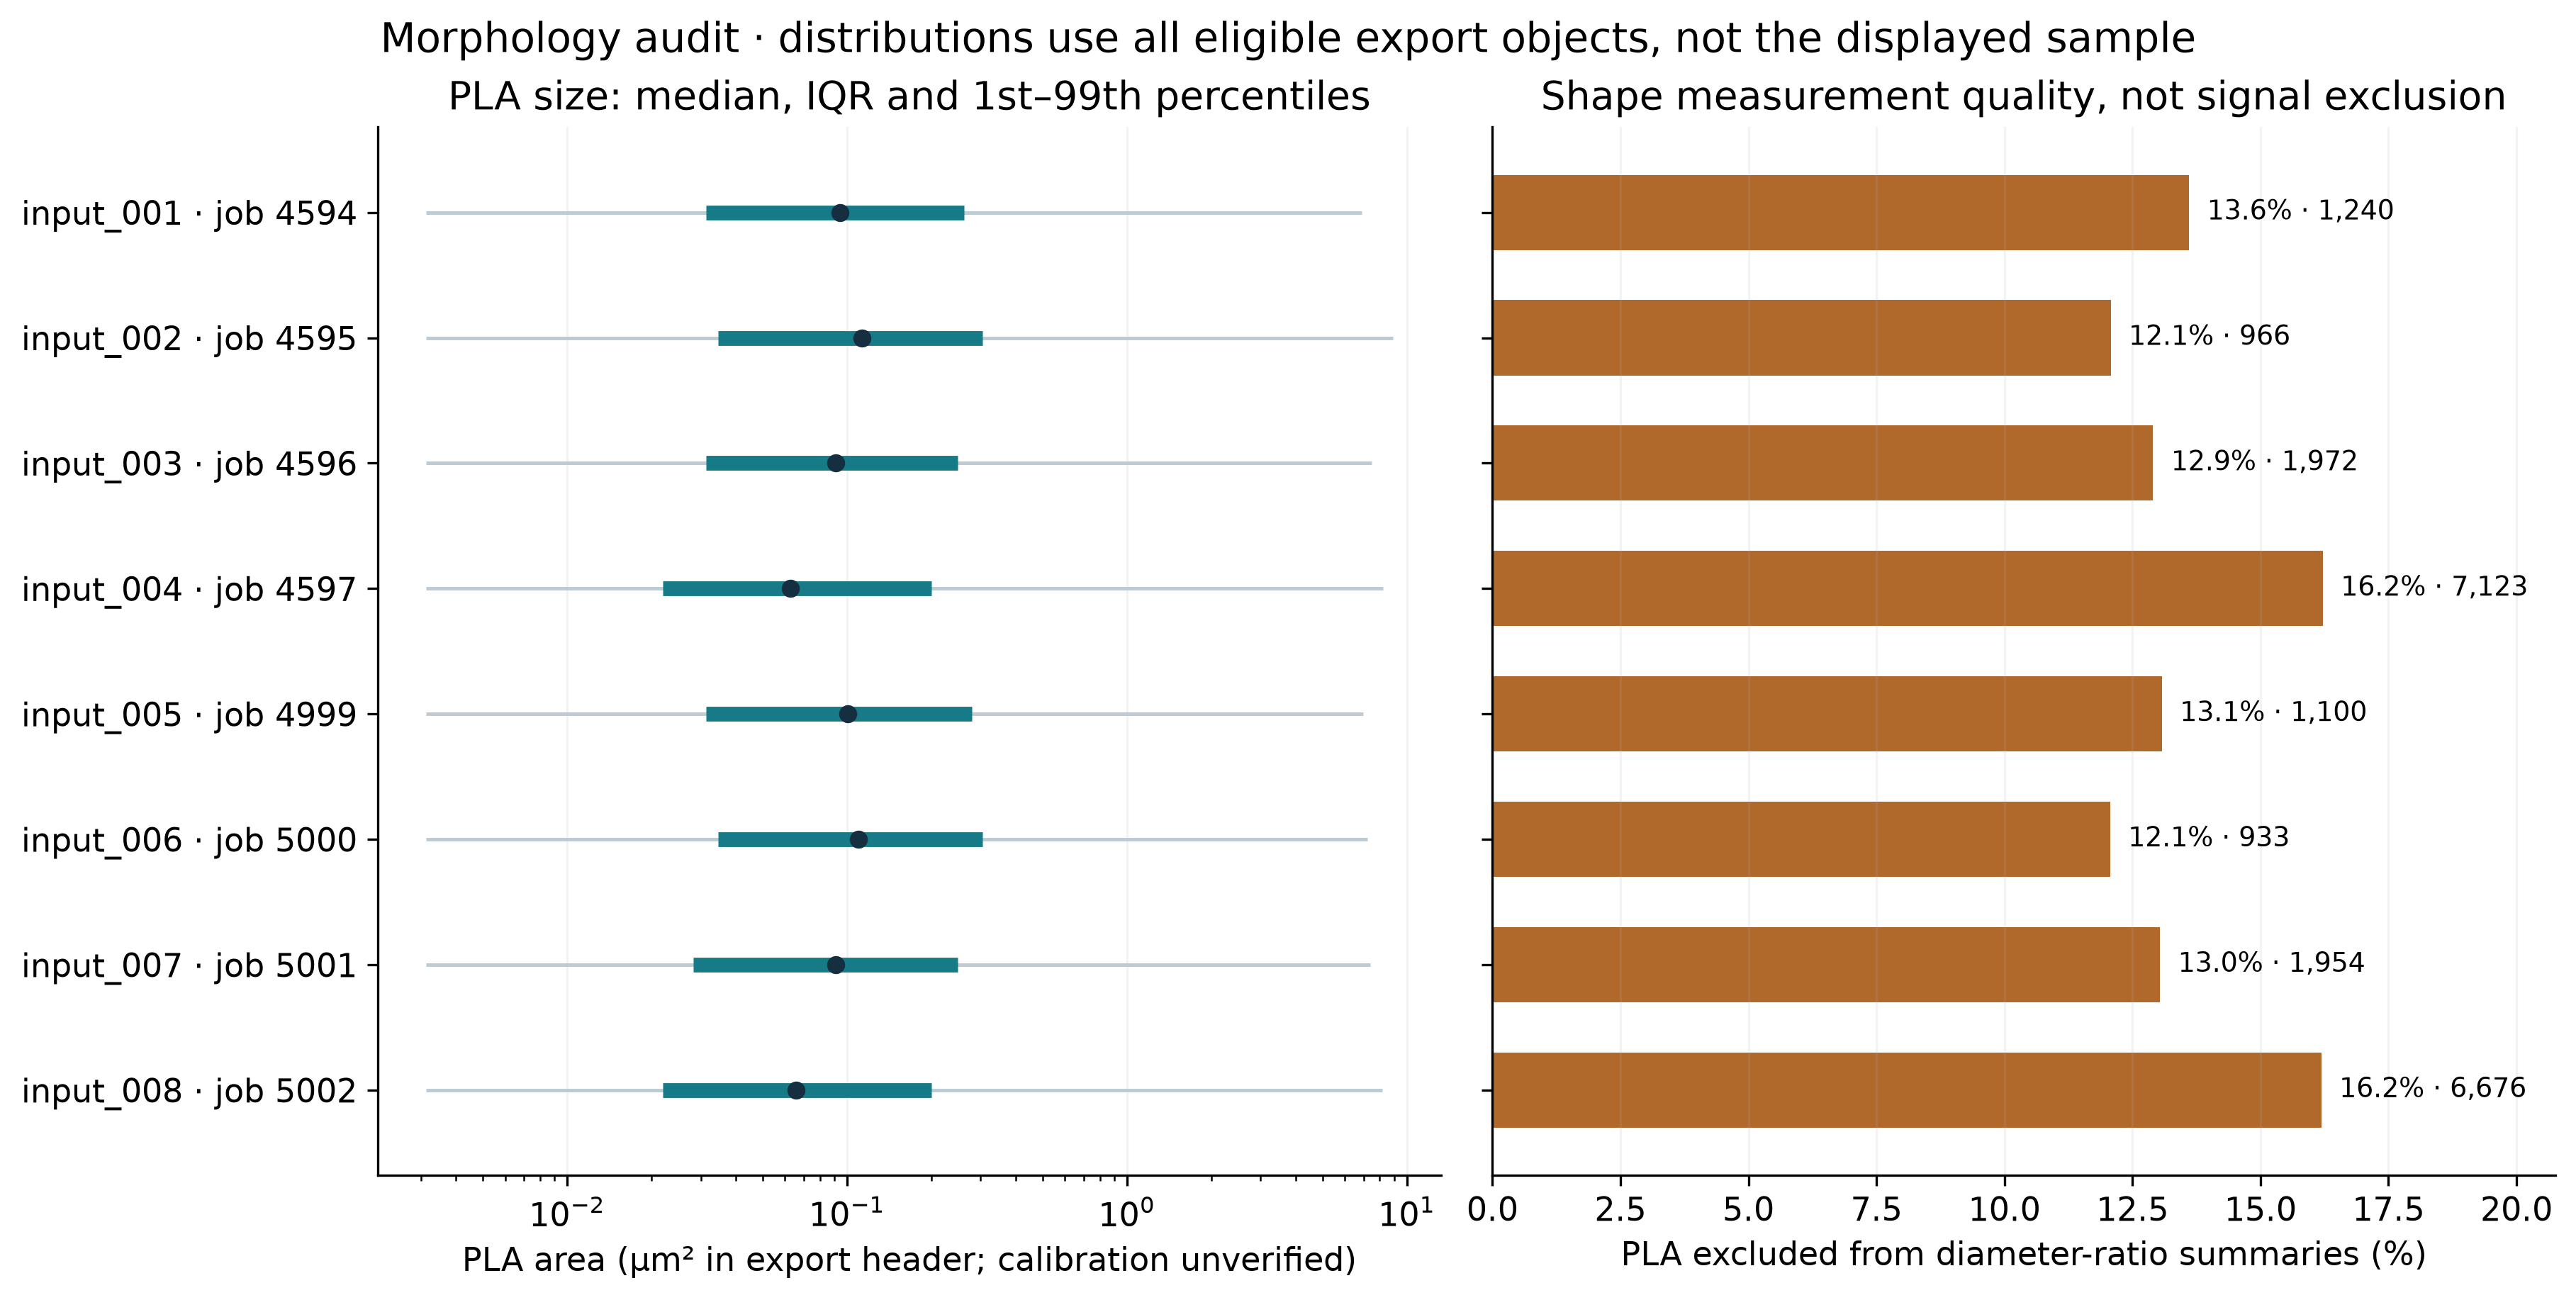

**Source-image review windows:** selected examples for follow-up, not prevalence estimates. Counts and flags come from the source export; native windows are not tissue ROIs.

,file_id,job_id,source_filename,source_sha256,review_reason,rank_within_reason,x_bin,y_bin,xmin,xmax,ymin,ymax,PLA_count,PLA_ChAT_flag_positive,PLA_ChAT_flag_fraction,ChAT_count,coordinate_units,coordinate_proxy,tissue_coverage_status,scientific_status
0,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,high_raw_PLA_count,1,161,41,22144.0,22272.0,5248.0,5376.0,294,294,1.000000,7,unverified native export units,bounding-box midpoint,"unknown; rectangular exported-search bin, no t...",Selected extreme for manual image/segmentation...
1,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,high_raw_PLA_count,2,161,40,22144.0,22272.0,5120.0,5248.0,89,88,0.988764,4,unverified native export units,bounding-box midpoint,"unknown; rectangular exported-search bin, no t...",Selected extreme for manual image/segmentation...
2,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,high_raw_PLA_count,3,140,35,19456.0,19584.0,4480.0,4608.0,59,52,0.881356,38,unverified native export units,bounding-box midpoint,"unknown; rectangular exported-search bin, no t...",Selected extreme for manual image/segmentation...
3,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,high_raw_PLA_count,4,141,31,19584.0,19712.0,3968.0,4096.0,44,13,0.295455,55,unverified native export units,bounding-box midpoint,"unknown; rectangular exported-search bin, no t...",Selected extreme for manual image/segmentation...
4,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,high_raw_PLA_count,5,139,24,19328.0,19456.0,3072.0,3200.0,36,25,0.694444,22,unverified native export units,bounding-box midpoint,"unknown; rectangular exported-search bin, no t...",Selected extreme for manual image/segmentation...
5,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,low_ChAT_flag_fraction_min20_PLA,1,141,31,19584.0,19712.0,3968.0,4096.0,44,13,0.295455,55,unverified native export units,bounding-box midpoint,"unknown; rectangular exported-search bin, no t...",Selected extreme for manual image/segmentation...
6,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,low_ChAT_flag_fraction_min20_PLA,2,146,36,20224.0,20352.0,4608.0,4736.0,31,10,0.322581,35,unverified native export units,bounding-box midpoint,"unknown; rectangular exported-search bin, no t...",Selected extreme for manual image/segmentation...
7,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,low_ChAT_flag_fraction_min20_PLA,3,148,38,20480.0,20608.0,4864.0,4992.0,33,11,0.333333,22,unverified native export units,bounding-box midpoint,"unknown; rectangular exported-search bin, no t...",Selected extreme for manual image/segmentation...
8,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,high_ChAT_flag_fraction_min20_PLA,1,161,41,22144.0,22272.0,5248.0,5376.0,294,294,1.000000,7,unverified native export units,bounding-box midpoint,"unknown; rectangular exported-search bin, no t...",Selected extreme for manual image/segmentation...
9,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,high_ChAT_flag_fraction_min20_PLA,2,108,58,15360.0,15488.0,7424.0,7552.0,28,28,1.000000,6,unverified native export units,bounding-box midpoint,"unknown; rectangular exported-search bin, no t...",Selected extreme for manual image/segmentation...


In [6]:
display(Image(filename=str(ROOT/'outputs/native_atlas/figures/export_morphology_quality.png'),width=1100))
targets=pd.read_csv(ROOT/'outputs/native_atlas/review_targets.csv')
display(Markdown('**Source-image review windows:** selected examples for follow-up, not prevalence estimates. Counts and flags come from the source export; native windows are not tissue ROIs.'))
display(targets.head(16))

Morphology targets below are selected from the **complete source objects**, independently of the capped display sample. They retain exact object IDs and source-record numbers, bounding boxes, measurements and reasons. An object can be selected for more than one reason. Review does not remove it from count or association denominators.

In [7]:
morphology_targets=pd.read_csv(ROOT/'outputs/native_atlas/morphology_object_review_targets.csv')
display(morphology_targets.head(16))

,file_id,job_id,source_filename,source_sha256,source_row_index_zero_based,source_csv_record_number_including_header,object_id,object_type,exported_analysis_region,review_reason,...,diameter_ratio_minimum_over_maximum,diameter_ratio_eligible,exported_ChAT_flag,retained_in_raw_PLA_count,coordinate_units,area_units,diameter_units,coordinate_proxy,selection_scope,scientific_status
0,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,1016,1018,1016,PLA - TRITC_E1,22M_Pfkp-TDP43 PLA,diameter_ratio_ineligible_inspect_measurement_...,...,NaN,False,0.0,True,unverified native export units,µm² in export header; calibration unverified,µm in export header; calibration unverified,"bounding-box midpoint, not a measured centroid","Full export PLA records, not the displayed poi...",Targeted original-image/segmentation QC; not r...
1,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,1152,1154,1152,PLA - TRITC_E1,22M_Pfkp-TDP43 PLA,diameter_ratio_ineligible_inspect_measurement_...,...,NaN,False,1.0,True,unverified native export units,µm² in export header; calibration unverified,µm in export header; calibration unverified,"bounding-box midpoint, not a measured centroid","Full export PLA records, not the displayed poi...",Targeted original-image/segmentation QC; not r...
2,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,2102,2104,2102,PLA - TRITC_E1,22M_Pfkp-TDP43 PLA,diameter_ratio_ineligible_inspect_measurement_...,...,NaN,False,1.0,True,unverified native export units,µm² in export header; calibration unverified,µm in export header; calibration unverified,"bounding-box midpoint, not a measured centroid","Full export PLA records, not the displayed poi...",Targeted original-image/segmentation QC; not r...
3,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,2518,2520,2518,PLA - TRITC_E1,22M_Pfkp-TDP43 PLA,diameter_ratio_ineligible_inspect_measurement_...,...,NaN,False,1.0,True,unverified native export units,µm² in export header; calibration unverified,µm in export header; calibration unverified,"bounding-box midpoint, not a measured centroid","Full export PLA records, not the displayed poi...",Targeted original-image/segmentation QC; not r...
4,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,46,48,46,PLA - TRITC_E1,22M_Pfkp-TDP43 PLA,zero_minimum_positive_maximum_retained_ratio_zero,...,0.000000,True,0.0,True,unverified native export units,µm² in export header; calibration unverified,µm in export header; calibration unverified,"bounding-box midpoint, not a measured centroid","Full export PLA records, not the displayed poi...",Targeted original-image/segmentation QC; not r...
5,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,403,405,403,PLA - TRITC_E1,22M_Pfkp-TDP43 PLA,zero_minimum_positive_maximum_retained_ratio_zero,...,0.000000,True,0.0,True,unverified native export units,µm² in export header; calibration unverified,µm in export header; calibration unverified,"bounding-box midpoint, not a measured centroid","Full export PLA records, not the displayed poi...",Targeted original-image/segmentation QC; not r...
6,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2_...,83839e1e12719dd022d1e594a8effec80ba1059bcb3af2...,2518,2520,2518,PLA - TRITC_E1,22M_Pfkp-TDP43 PLA,smallest_positive_finite_exported_PLA_area,...,NaN,False,1.0,True,unverified native export units,µm² in export header; calibration unverified,µm in export header; calibration unverified,"bounding-box midpoint, not a measured centroid","Full export PLA records, not the displayed poi...",Targeted original-image/segmentation QC; not r...
7,input_001,4594,20260515_173745_2_jqw0p1_Ellie_PLA_051520

## 5. Verified former findings and the visual practices carried forward

The previous analysis used the **historical expanded PLA–ChAT dataset**: twelve retained sections, six animals, three animals per condition. Its saved results are shown here as historical context with checked provenance. They are not recalculated from the current eight overlapping exports, and their group assignments do not become current metadata.

The main transferable practices are specimen-level displays, explicit denominators, shared map scales, native channel overlays, sensitivity comparisons, source-coordinate review and a question/evidence/limit/next explanation for every major result. The new viewer brings these practices into the current project without promoting old registration proposals into accepted anatomy.

### Historical association contrast: consistent direction in both PLA arms

**Historical finding:** Home cage was higher by 22.01 percentage points in HK1 and 22.58 points in PFKP. Historical means: HK1 53.59% versus 31.58%; PFKP 73.20% versus 50.62%.

**Evidence:** For every mouse, 100 × ChAT-positive PLA / all PLA; average three mouse percentages equally in each group, separately by arm. Values verified from saved animal numerators/denominators and condition_contrasts.csv.gz.

**Limit:** These are former-dataset descriptions with three animals per condition. ChAT association does not establish molecular binding, cell identity, metabolic flux or a causal running effect. They are not current COMET count-map findings.

**Practice transferred / next:** Reuse the result presentation: retain the experimental unit, state the numerator and denominator, show all specimen values and keep both PLA arms separate.

### Historical sensitivity checks narrowed one explanation

**Historical finding:** With a common PLA-size mixture, the Home − Running gap was 23.47 points (HK1) and 24.07 points (PFKP). A common learned size/shape mixture gave 22.89 and 23.30 points.

**Evidence:** Saved condition_standardization.csv.gz rows estimator=standardized; ml_standardized.csv.gz rows k=3. Both retain the positive association gap.

**Limit:** These are sensitivity analyses of the old ChAT fraction, not tissue-area correction or proof that the contrast is biological. The new PDF prohibits normalization and statistical testing in the first count-map pass (p. 2).

**Practice transferred / next:** Reuse explicit estimand explanations and side-by-side support panels. Keep historical standardization and clustering outside current required count-map calculations.

### Historical animal omissions preserved the contrast direction

**Historical finding:** Omitting one mouse from each group in all nine combinations gave HK1 +16.16 to +30.80 points and PFKP +19.22 to +27.59 points.

**Evidence:** Saved condition_contrasts.csv.gz leave_pair_out_min/max for association_pct.

**Limit:** These nine comparisons reuse the same six animals. The ranges are sensitivity ranges, not confidence intervals or nine independent replications.

**Practice transferred / next:** Carry forward the practice of showing specimen-level variation and honest uncertainty labels when an authorized current analysis supports them.

### Historical source-image layout is a concrete technical-review priority

**Historical finding:** Across all 12 former sections, Running occupied lower X and Home cage higher X. All six within-source-image/arm association differences were positive.

**Evidence:** Saved condition_image_layout_summary.json: complete_condition_x_separation=true, source_image_count=3, positive_within_image_contrasts=6 of 6.

**Limit:** Coordinate layout alone does not establish an imaging artifact. A coordinate offset added after detection cannot itself change association. Shared source-image IDs do not establish biological pairing.

**Practice transferred / next:** Inspect original channels, composite provenance, illumination/background and HALO thresholds in comparable blinded fields; for current data, audit source-image and acquisition metadata independently.

### Historical morphology QC retained the primary denominator

**Historical finding:** 49,618 of 310,024 historical PLA detections (16.0%) lacked usable diameter ratios. They were excluded from shape modeling but remained in primary association results.

**Evidence:** Summed all 12 rows of ml_audit.csv.gz: 260,406 eligible and 49,618 excluded. Area-only sensitivity used all 310,024 PLA.

**Limit:** Exploratory clusters describe measured size/shape patterns, not validated cell types. Neither exclusions nor learned group boundaries should be transferred to a new experiment without evidence.

**Practice transferred / next:** Reuse separate exclusion reporting and native-coordinate microscopy review targets. Preserve current full-detection counts unless a documented current selection rule says otherwise.

### Historical alignment figures are proposals, not accepted current geometry

**Historical finding:** The accessible historical review records contain 0/12 fully approved sections. All 12 sections have inspectable computational geometry proposals, but no supplied accepted tissue masks were identified.

**Evidence:** metadata/handoff_section_reviews.json plus alignment_proposals.json and the caption of 19_feature_alignment_before_after.png.

**Limit:** The newer instruction PDF says an alignment was accepted and asks to preserve it (p. 1). The historical proposal assets do not identify that accepted numerical asset. This discrepancy is an asset/provenance gap, not a request to repeat scientific approval.

**Practice transferred / next:** Locate the already accepted transforms, masks, reference, exact section mapping and check figure. Preserve current native-coordinate maps now; apply the accepted geometry unchanged when matched.

**HISTORICAL EXPANDED PLA–ChAT DATASET — 12 retained sections from six animals, three animals per condition per arm. Dots are mice; thick bars are equal-animal means. Left panels show ChAT-positive PLA / all PLA. Right panels show summed overlap area / summed PLA area, a different outcome. Black ranges omit one animal per group and are sensitivity ranges, not confidence intervals. These are not current COMET count-map results.**

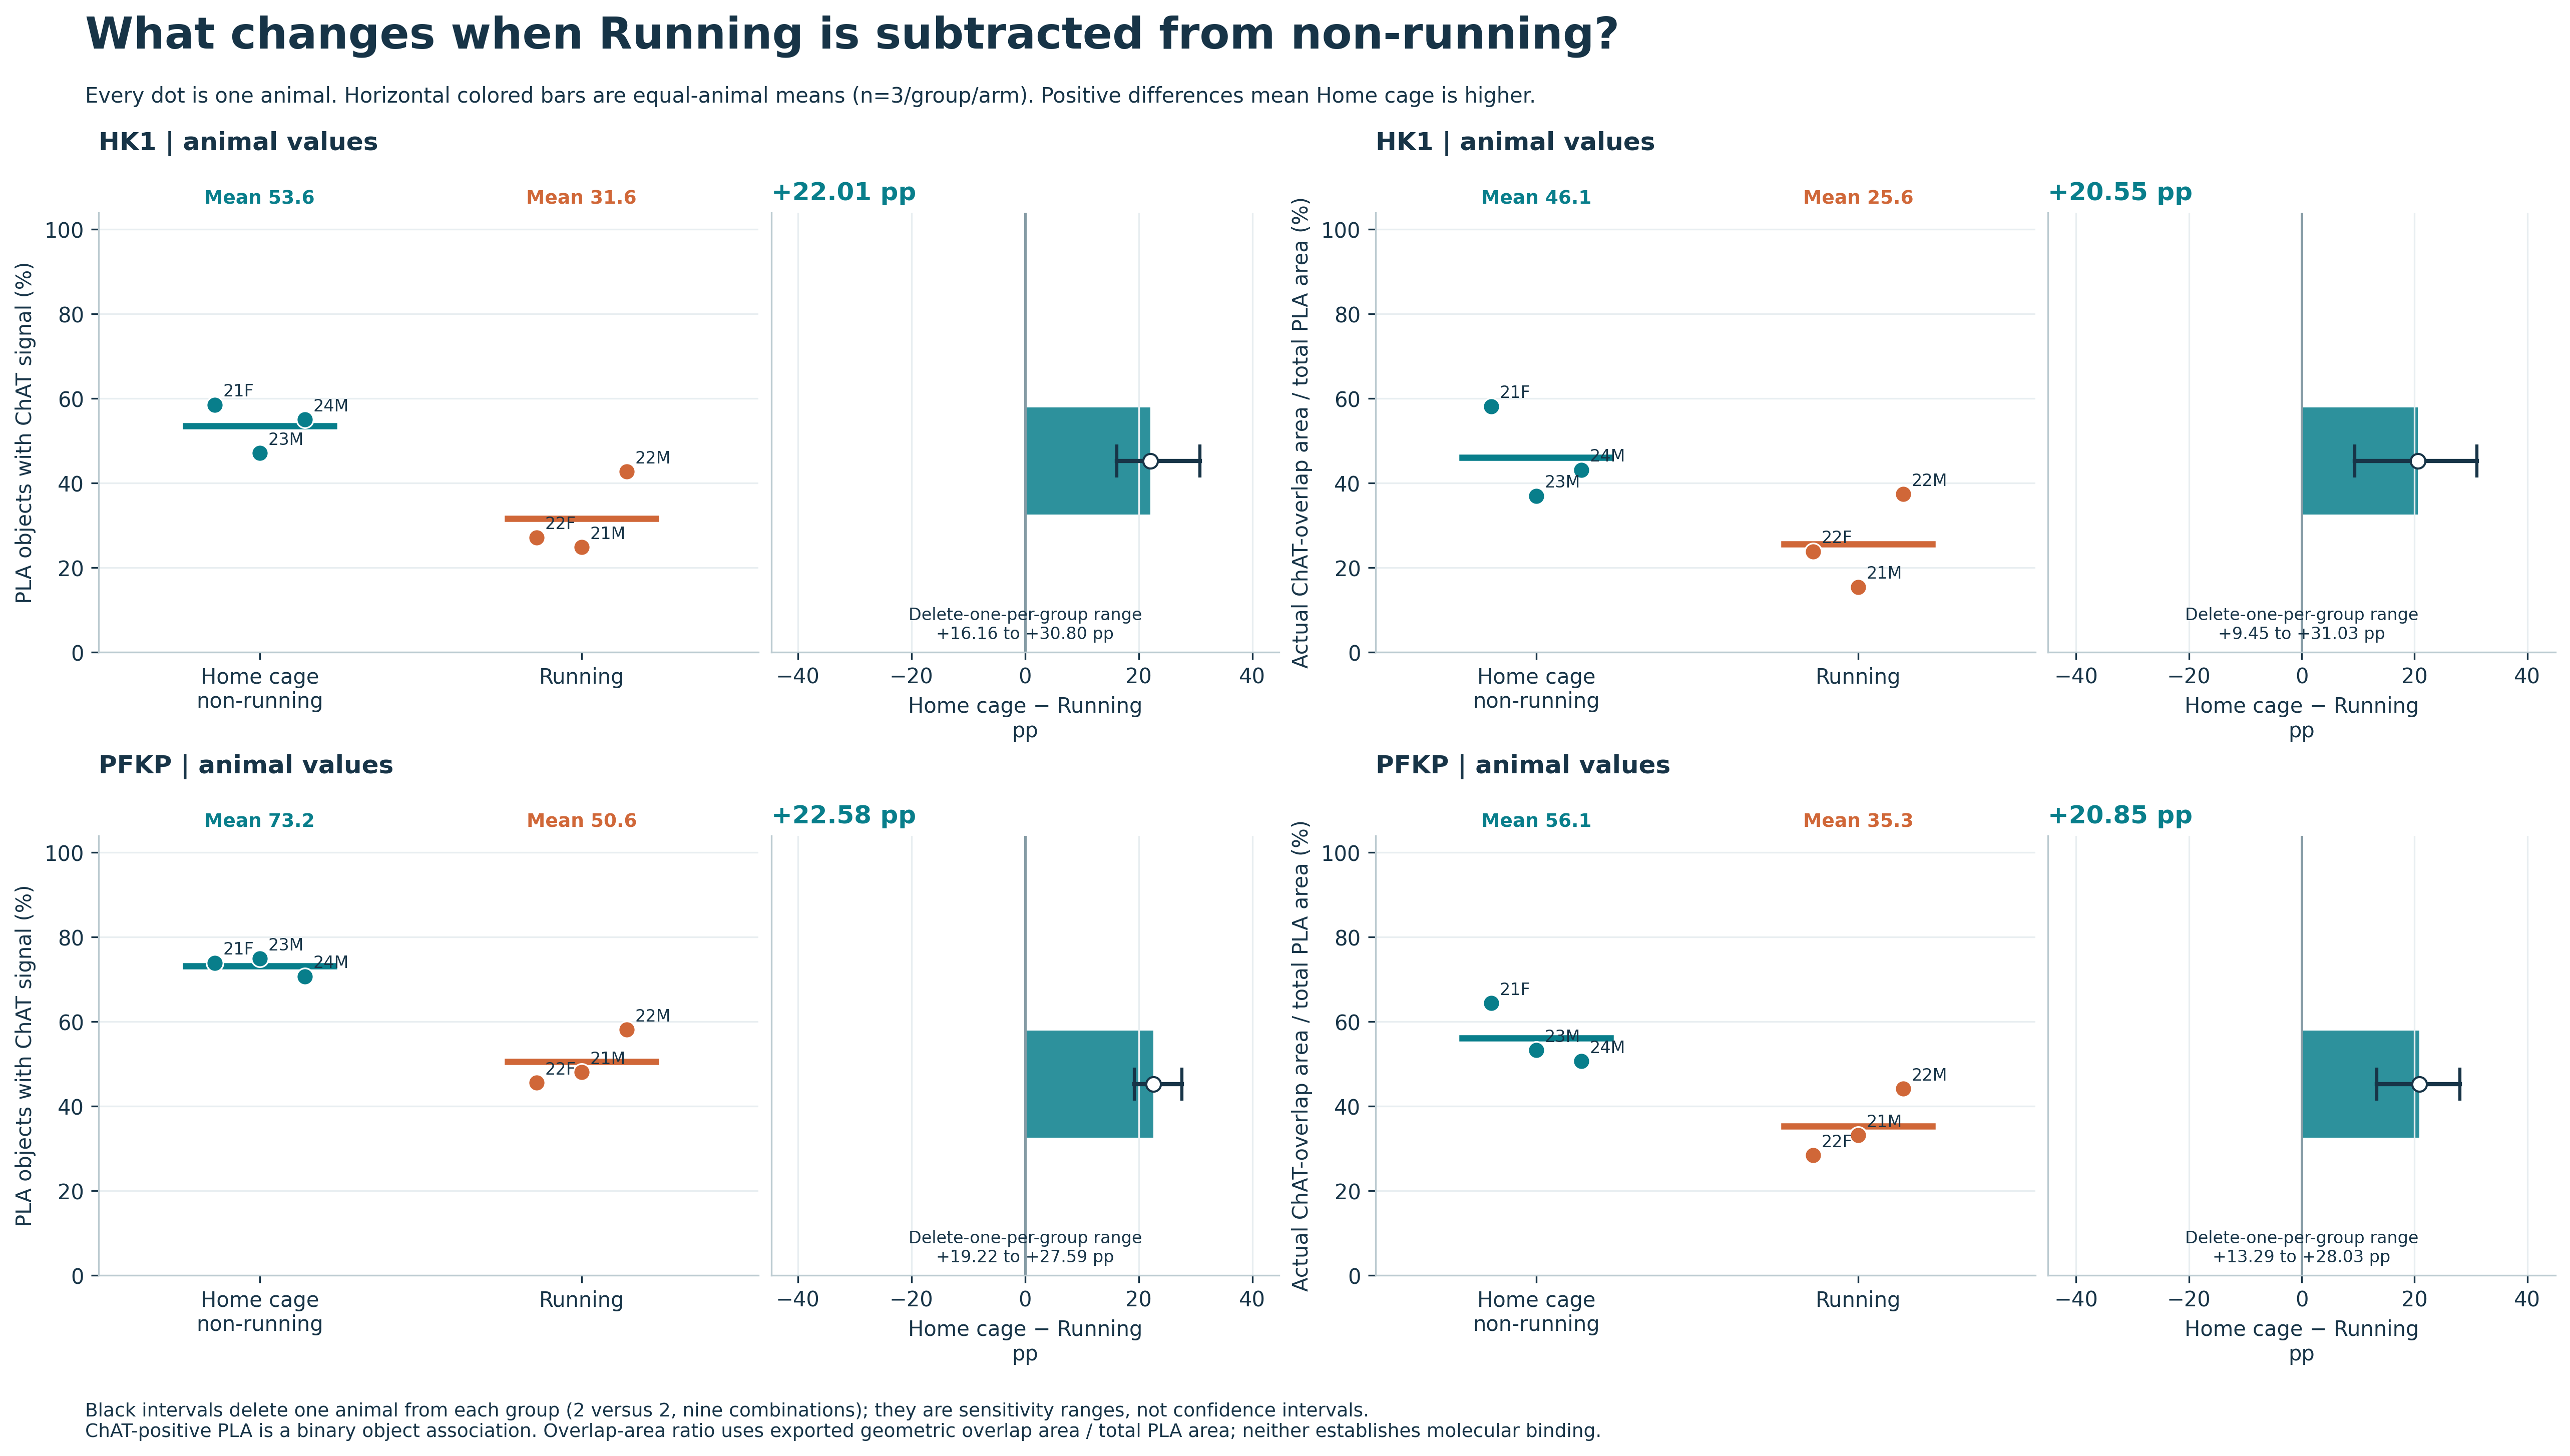

**HISTORICAL EXPANDED PLA–ChAT DATASET — six HK1 sections shown separately. Gray is ChAT midpoint count and color is PLA midpoint count in 100 × 100 export-unit bins, using shared scales within this arm. These are unsmoothed detection reconstructions, not microscopy pixels, accepted anatomical alignment, or current-data maps.**

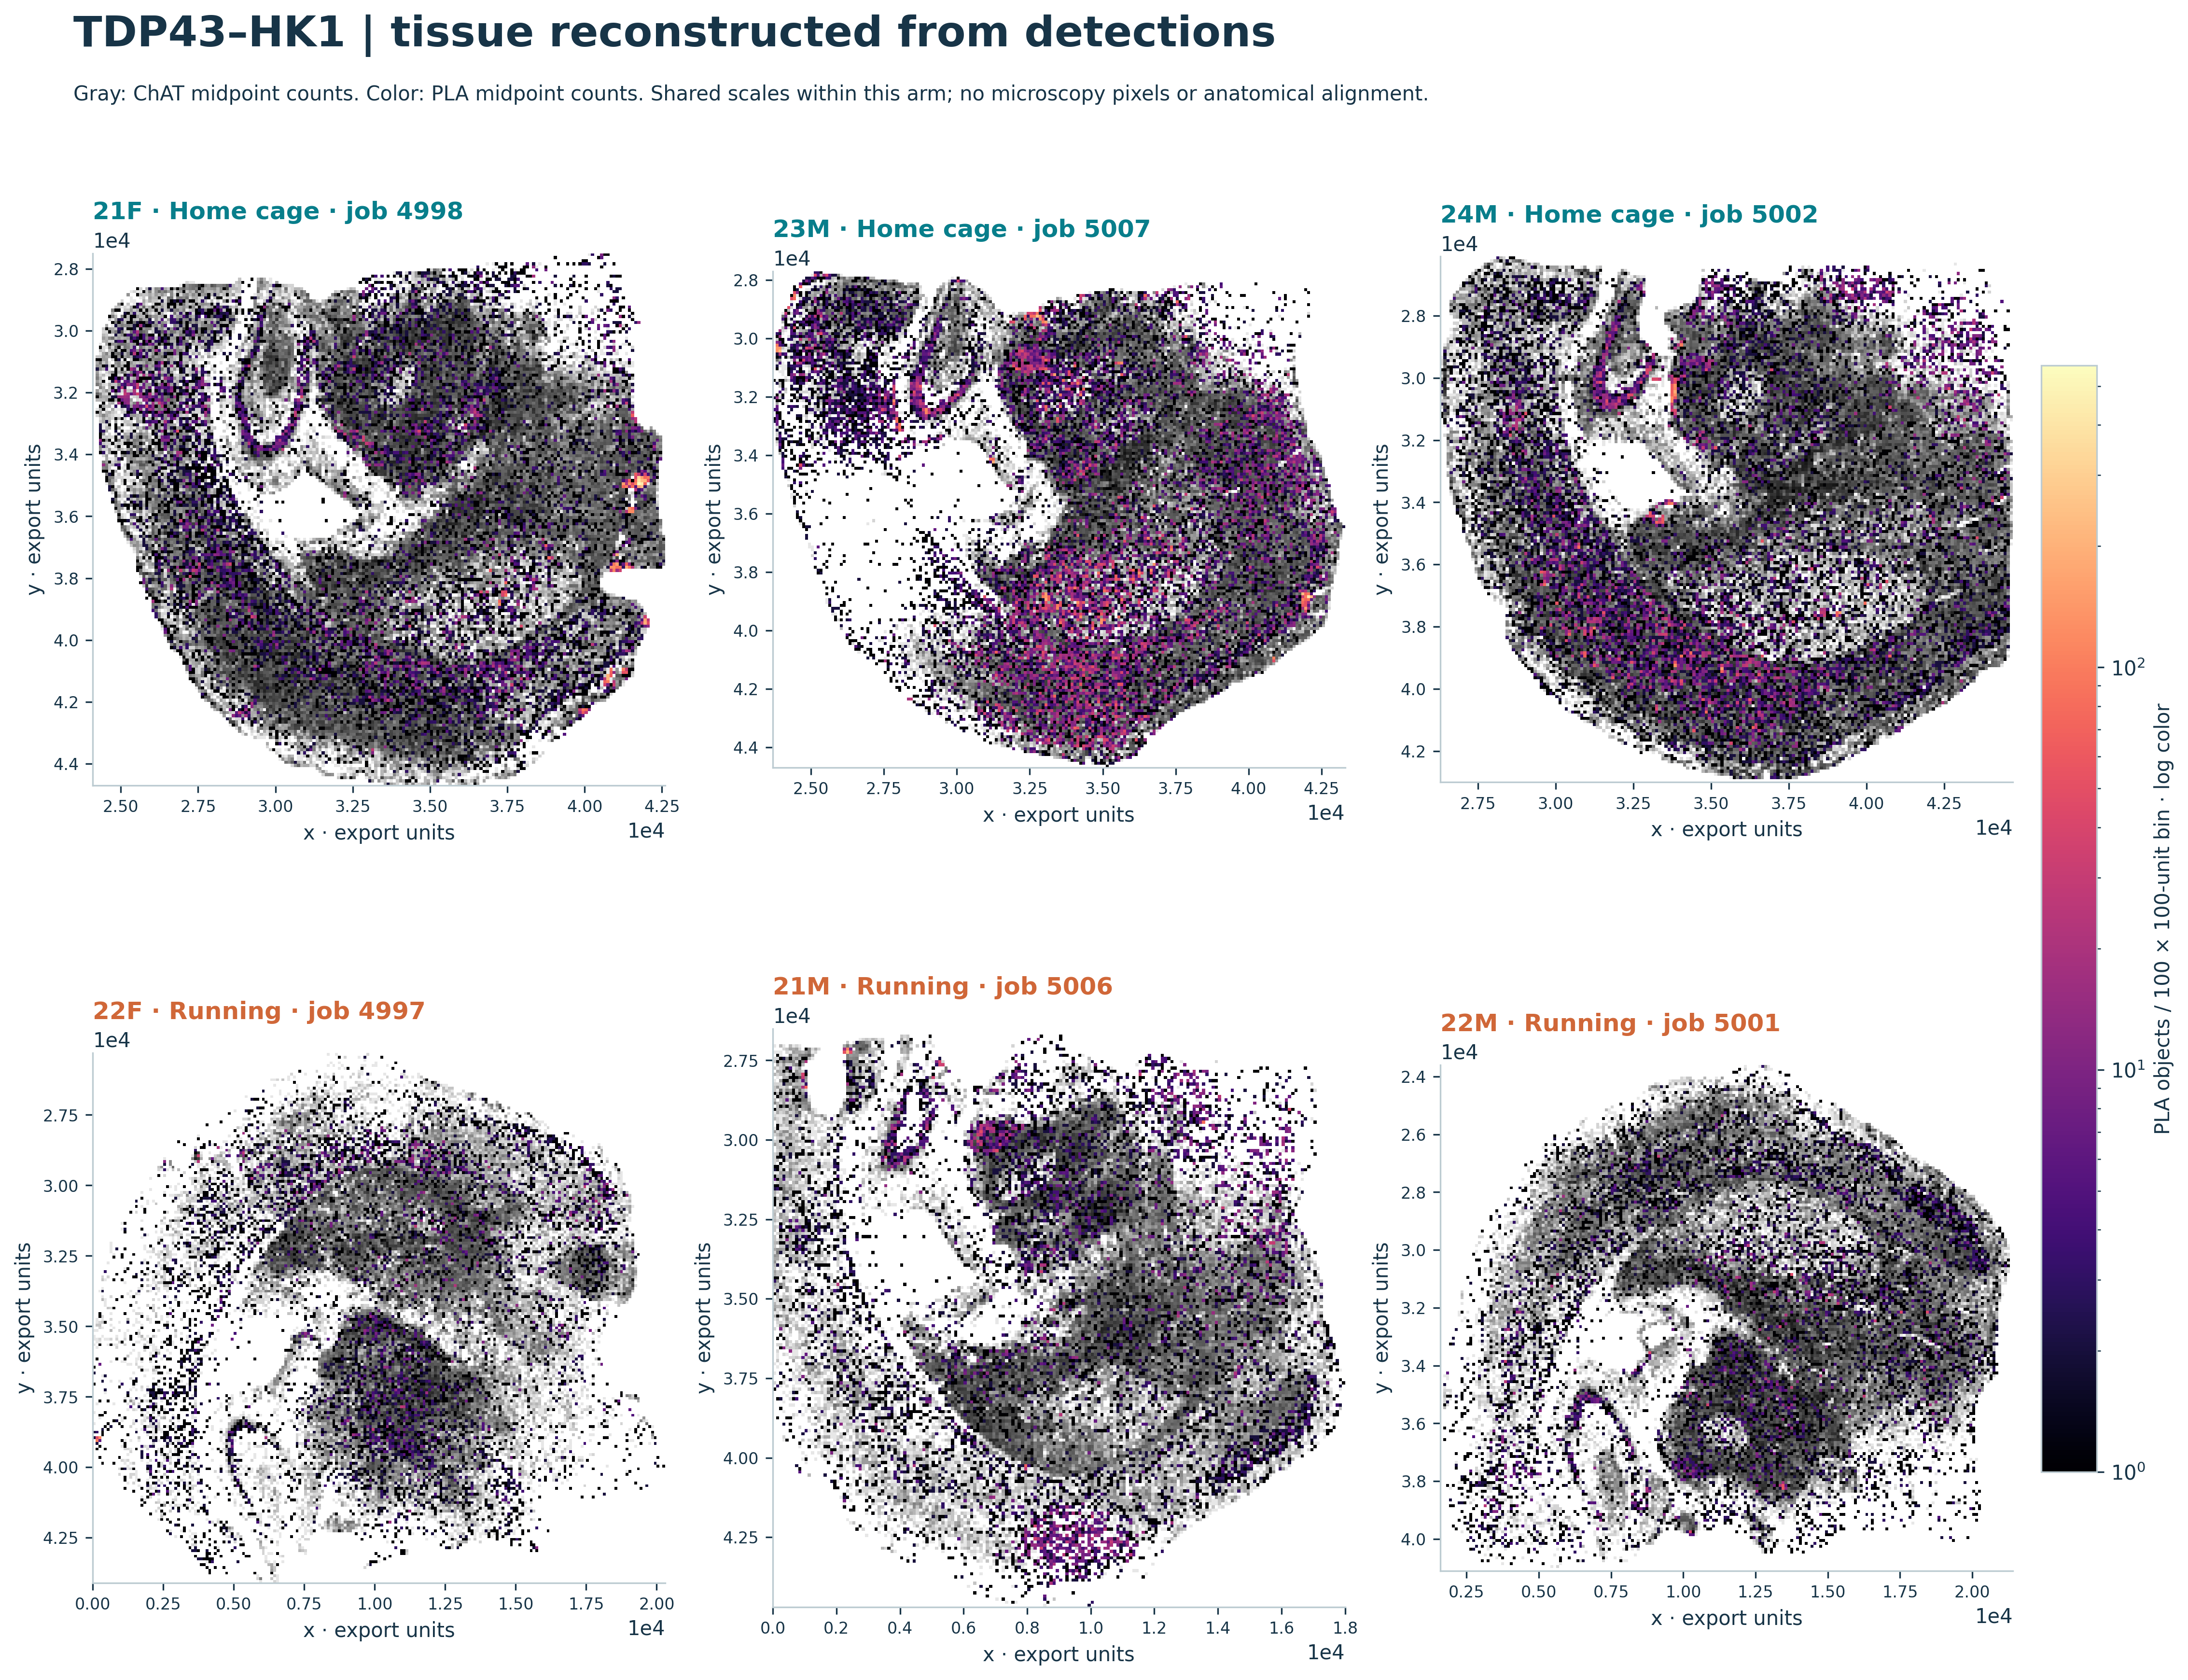

Historical remote main: 4631e1517f85de2c4bfb59879bf44f406770a903 ; see source hashes in historical_context.json.


In [8]:
history=json.loads((ROOT/'outputs/native_atlas/historical_context.json').read_text())
for row in history['rows']:
    display(Markdown(f"### {row['title']}\n\n**Historical finding:** {row['finding']}\n\n**Evidence:** {row['evidence']}\n\n**Limit:** {row['limitation']}\n\n**Practice transferred / next:** {row['next_step']}"))
for figure in history['figures'][:2]:
    display(Markdown('**'+figure['caption']+'**'))
    display(Image(filename=str(ROOT/figure['path']),width=1100))
print('Historical remote main:',history['remote_main'],'; see source hashes in historical_context.json.')

## 6. Scope of the requested aligned comparison

Native reconstructions, descriptive export fractions and historical context are supporting analyses. The PDF's initial **aligned Running − Homecage count maps** retain their original contract: reuse accepted transforms/masks, strict full-bin coverage, valid zeros, section means, separate arms and no smoothing, normalization or tests. An optional native association map in the explorer has a different, explicitly shown denominator and is not that requested condition map.

The preflight below lists the missing numerical assets and sample relationships. It does not stop native exploration, and no native display proposes a new alignment or tissue mask. The 3D surface in the app shows a bin measurement as height; height is not anatomical depth.

## Question, design and intended decision

Where do the two conditions differ in spatial PLA object counts, separately for TDP43-HK1 and TDP43-PFKP? The maps will guide source-image review of supported regions. The new PDF documents two conditions and two arms, but does not give animal numbers, assignments, pairing, controls, tissue levels or treatment details (p. 1; IDs to preserve on p. 2).

The requested averaging unit is a **physical tissue section**. Animals are the biological experimental units; multiple sections/analyses of one animal are not independent animals. Equal-section weighting can differ from equal-animal weighting if section numbers differ. No inferential test is requested. Current sample metadata deliberately preserve unknown fields.

Rows are exported detected objects, not necessarily cells or individual molecules. Counts alone cannot demonstrate binding, metabolic activity or a causal effect of running.

In [9]:
sample_metadata = pd.read_csv(ROOT / 'metadata/sample_metadata.csv', keep_default_na=False)
display(sample_metadata)
print('Biological sample size and current section/condition assignments: unresolved.')

,file_id,exported_analysis_region,rows_in_export_region,animal_id,condition,pla_arm,physical_section_id,roi_id,biological_replicate_id,technical_repeat_of,include_in_primary_analysis,approved_alignment_id,aligned_centroid_source,tissue_mask_source,coordinate_units,assignment_status,evidence
0,input_001,22M_Pfkp-TDP43 PLA,186343,,,,,,,,pending,,,,unverified,unconfirmed_for_new_project,Analysis Region text observed in CSV; no trans...
1,input_002,24M_Pfkp-TDP43 PLA,297584,,,,,,,,pending,,,,unverified,unconfirmed_for_new_project,Analysis Region text observed in CSV; no trans...
2,input_003,22M_Hk1-TDP43 PLA,238084,,,,,,,,pending,,,,unverified,unconfirmed_for_new_project,Analysis Region text observed in CSV; no trans...
3,input_004,24M_Hk1-TDP43 PLA,356745,,,,,,,,pending,,,,unverified,unconfirmed_for_new_project,Analysis Region text observed in CSV; no trans...
4,input_005,22M_TDP43-Pfkp_tight,184684,,,,,,,,pending,,,,unverified,unconfirmed_for_new_project,Analysis Region text observed in CSV; no trans...
5,input_006,24M_TDP43-Pfkp_tight,295677,,,,,,,,pending,,,,unverified,unconfirmed_for_new_project,Analysis Region text observed in CSV; no trans...
6,input_007,22M_TDP43-Hk1_tight,237144,,,,,,,,pending,,,,unverified,unconfirmed_for_new_project,Analysis Region text observed in CSV; no trans...
7,input_008,24M_TDP43-Hk1_tight,349776,,,,,,,,pending,,,,unverified,unconfirmed_for_new_project,Analysis Region text observed in CSV; no trans...


Biological sample size and current section/condition assignments: unresolved.


## Input inventory and provenance

**Question:** what was actually supplied, and can the report be traced back to it?

**How to read:** each row below represents a file. Job numbers are filename tokens only; Analysis Region strings are literal export labels. The count of files is not the number of unique sections or animals. The inventory script read every CSV row and retained input hashes, column profiles and overlap evidence. The next cell verifies the bytes still match that inventory; it does not silently rescan or reinterpret the experiment.

In [10]:
display(pd.DataFrame(integrity))
display(pd.DataFrame(manifest)[['file_id','job_token_from_filename','exported_analysis_regions','row_count','historical_byte_identical_copy_count']])
print('Eight source hashes verified before the native analysis; detailed parsing validation is saved separately.')

,file_id,available,sha256_matches
0,input_001,True,True
1,input_002,True,True
2,input_003,True,True
3,input_004,True,True
4,input_005,True,True
5,input_006,True,True
6,input_007,True,True
7,input_008,True,True


,file_id,job_token_from_filename,exported_analysis_regions,row_count,historical_byte_identical_copy_count
0,input_001,4594,"[""22M_Pfkp-TDP43 PLA""]",186343,1
1,input_002,4595,"[""24M_Pfkp-TDP43 PLA""]",297584,1
2,input_003,4596,"[""22M_Hk1-TDP43 PLA""]",238084,1
3,input_004,4597,"[""24M_Hk1-TDP43 PLA""]",356745,1
4,input_005,4999,"[""22M_TDP43-Pfkp_tight""]",184684,2
5,input_006,5000,"[""24M_TDP43-Pfkp_tight""]",295677,2
6,input_007,5001,"[""22M_TDP43-Hk1_tight""]",237144,2
7,input_008,5002,"[""24M_TDP43-Hk1_tight""]",349776,2


Eight source hashes verified before the native analysis; detailed parsing validation is saved separately.


**Supported finding:** all eight supplied CSVs are byte-identical to historical inputs. This proves file-copy identity, not current experimental assignment. The user supplied these files for this project; no extra permission to use them is needed.

**Uncertainty / next investigation:** identify the physical sections and ROIs represented by each export, distinguish alternative analyses from unique sections, and select the intended primary analysis before aggregation. The next figures describe exports, not condition effects.

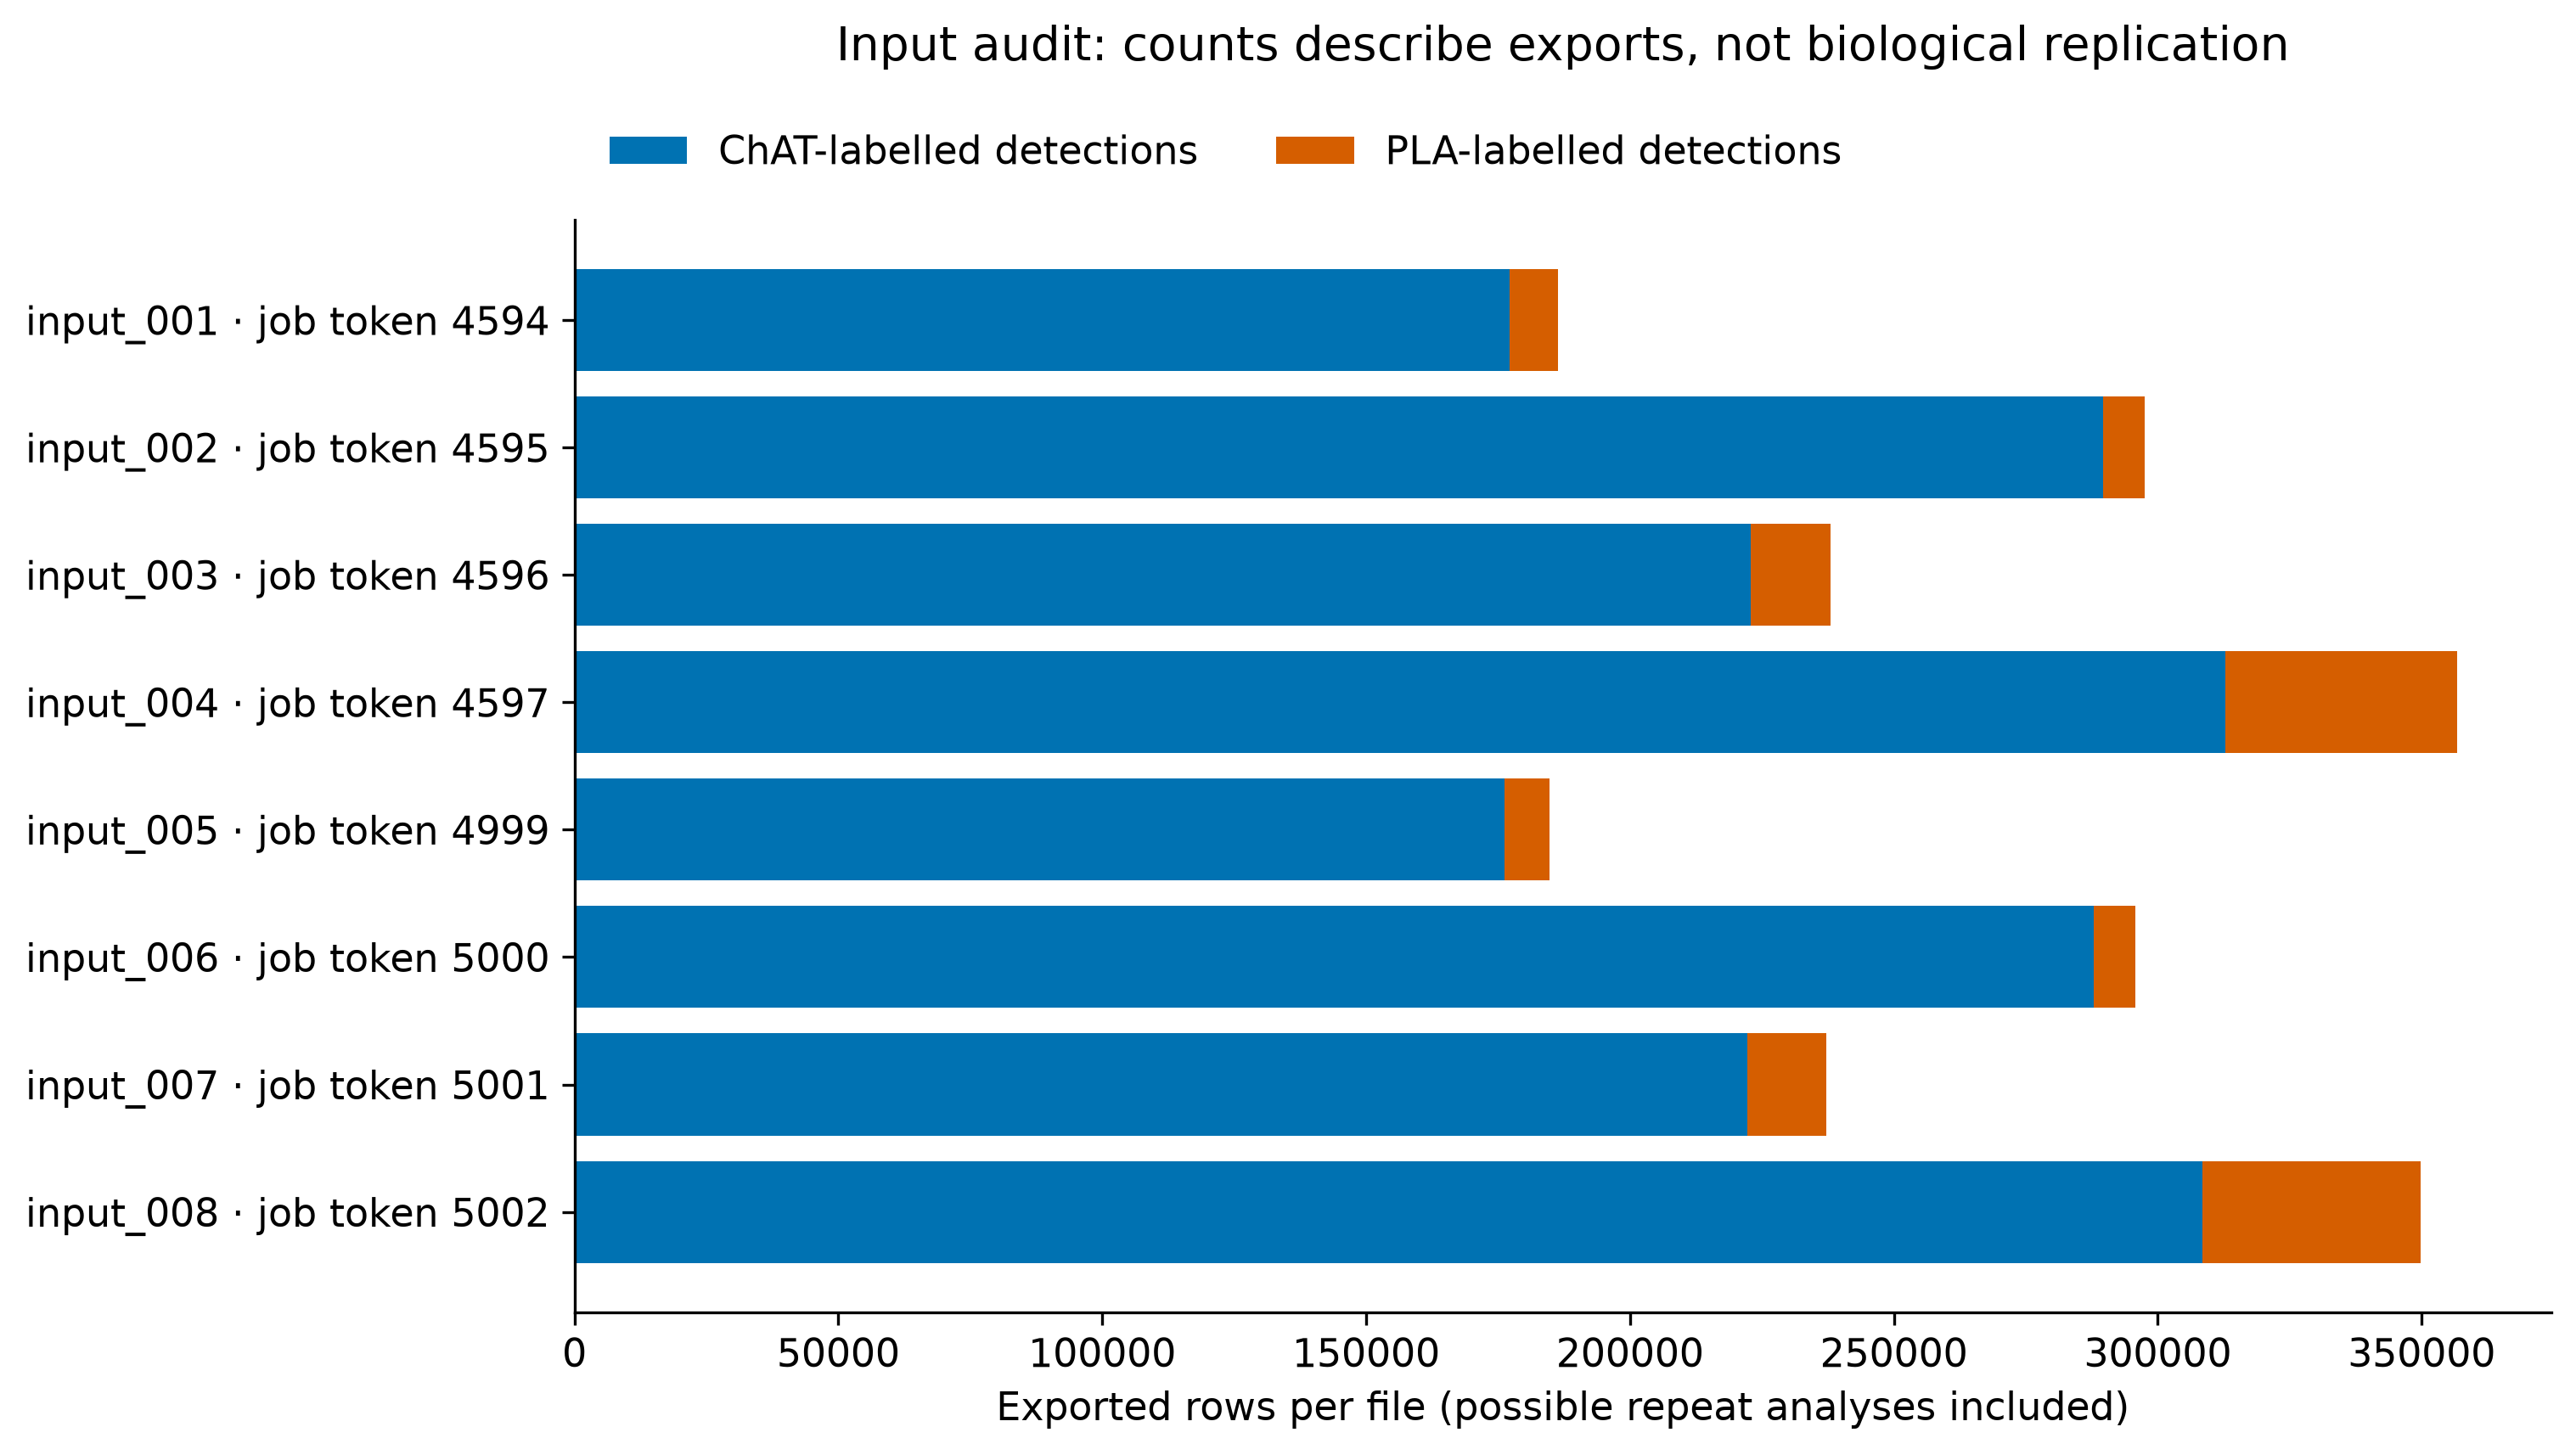

In [11]:
display(Image(filename=str(ROOT / 'outputs/figures/input_export_counts.png'), width=1000))

**Reading the export-count figure:** horizontal bars split each file's rows by the literal exported object-class label. Files with more rows do not receive more biological weight. Counts include possible repeated detections across exports; no cross-file total is an independent sample count.

**What to investigate next:** whether the overlapping exports are box-vs-outline analyses, different ROIs or reruns. No contour geometry is inferred from their labels.

,left_file_id,right_file_id,measurement_signatures_shared_excluding_region_and_object_id,left_signature_shared_fraction,right_signature_shared_fraction
21,input_004,input_008,331756,0.929958,0.948489
10,input_002,input_006,269574,0.905878,0.911721
16,input_003,input_007,218066,0.915924,0.919555
3,input_001,input_005,169352,0.908819,0.916983
0,input_001,input_002,0,0.000000,0.000000
15,input_003,input_006,0,0.000000,0.000000
26,input_006,input_008,0,0.000000,0.000000
25,input_006,input_007,0,0.000000,0.000000


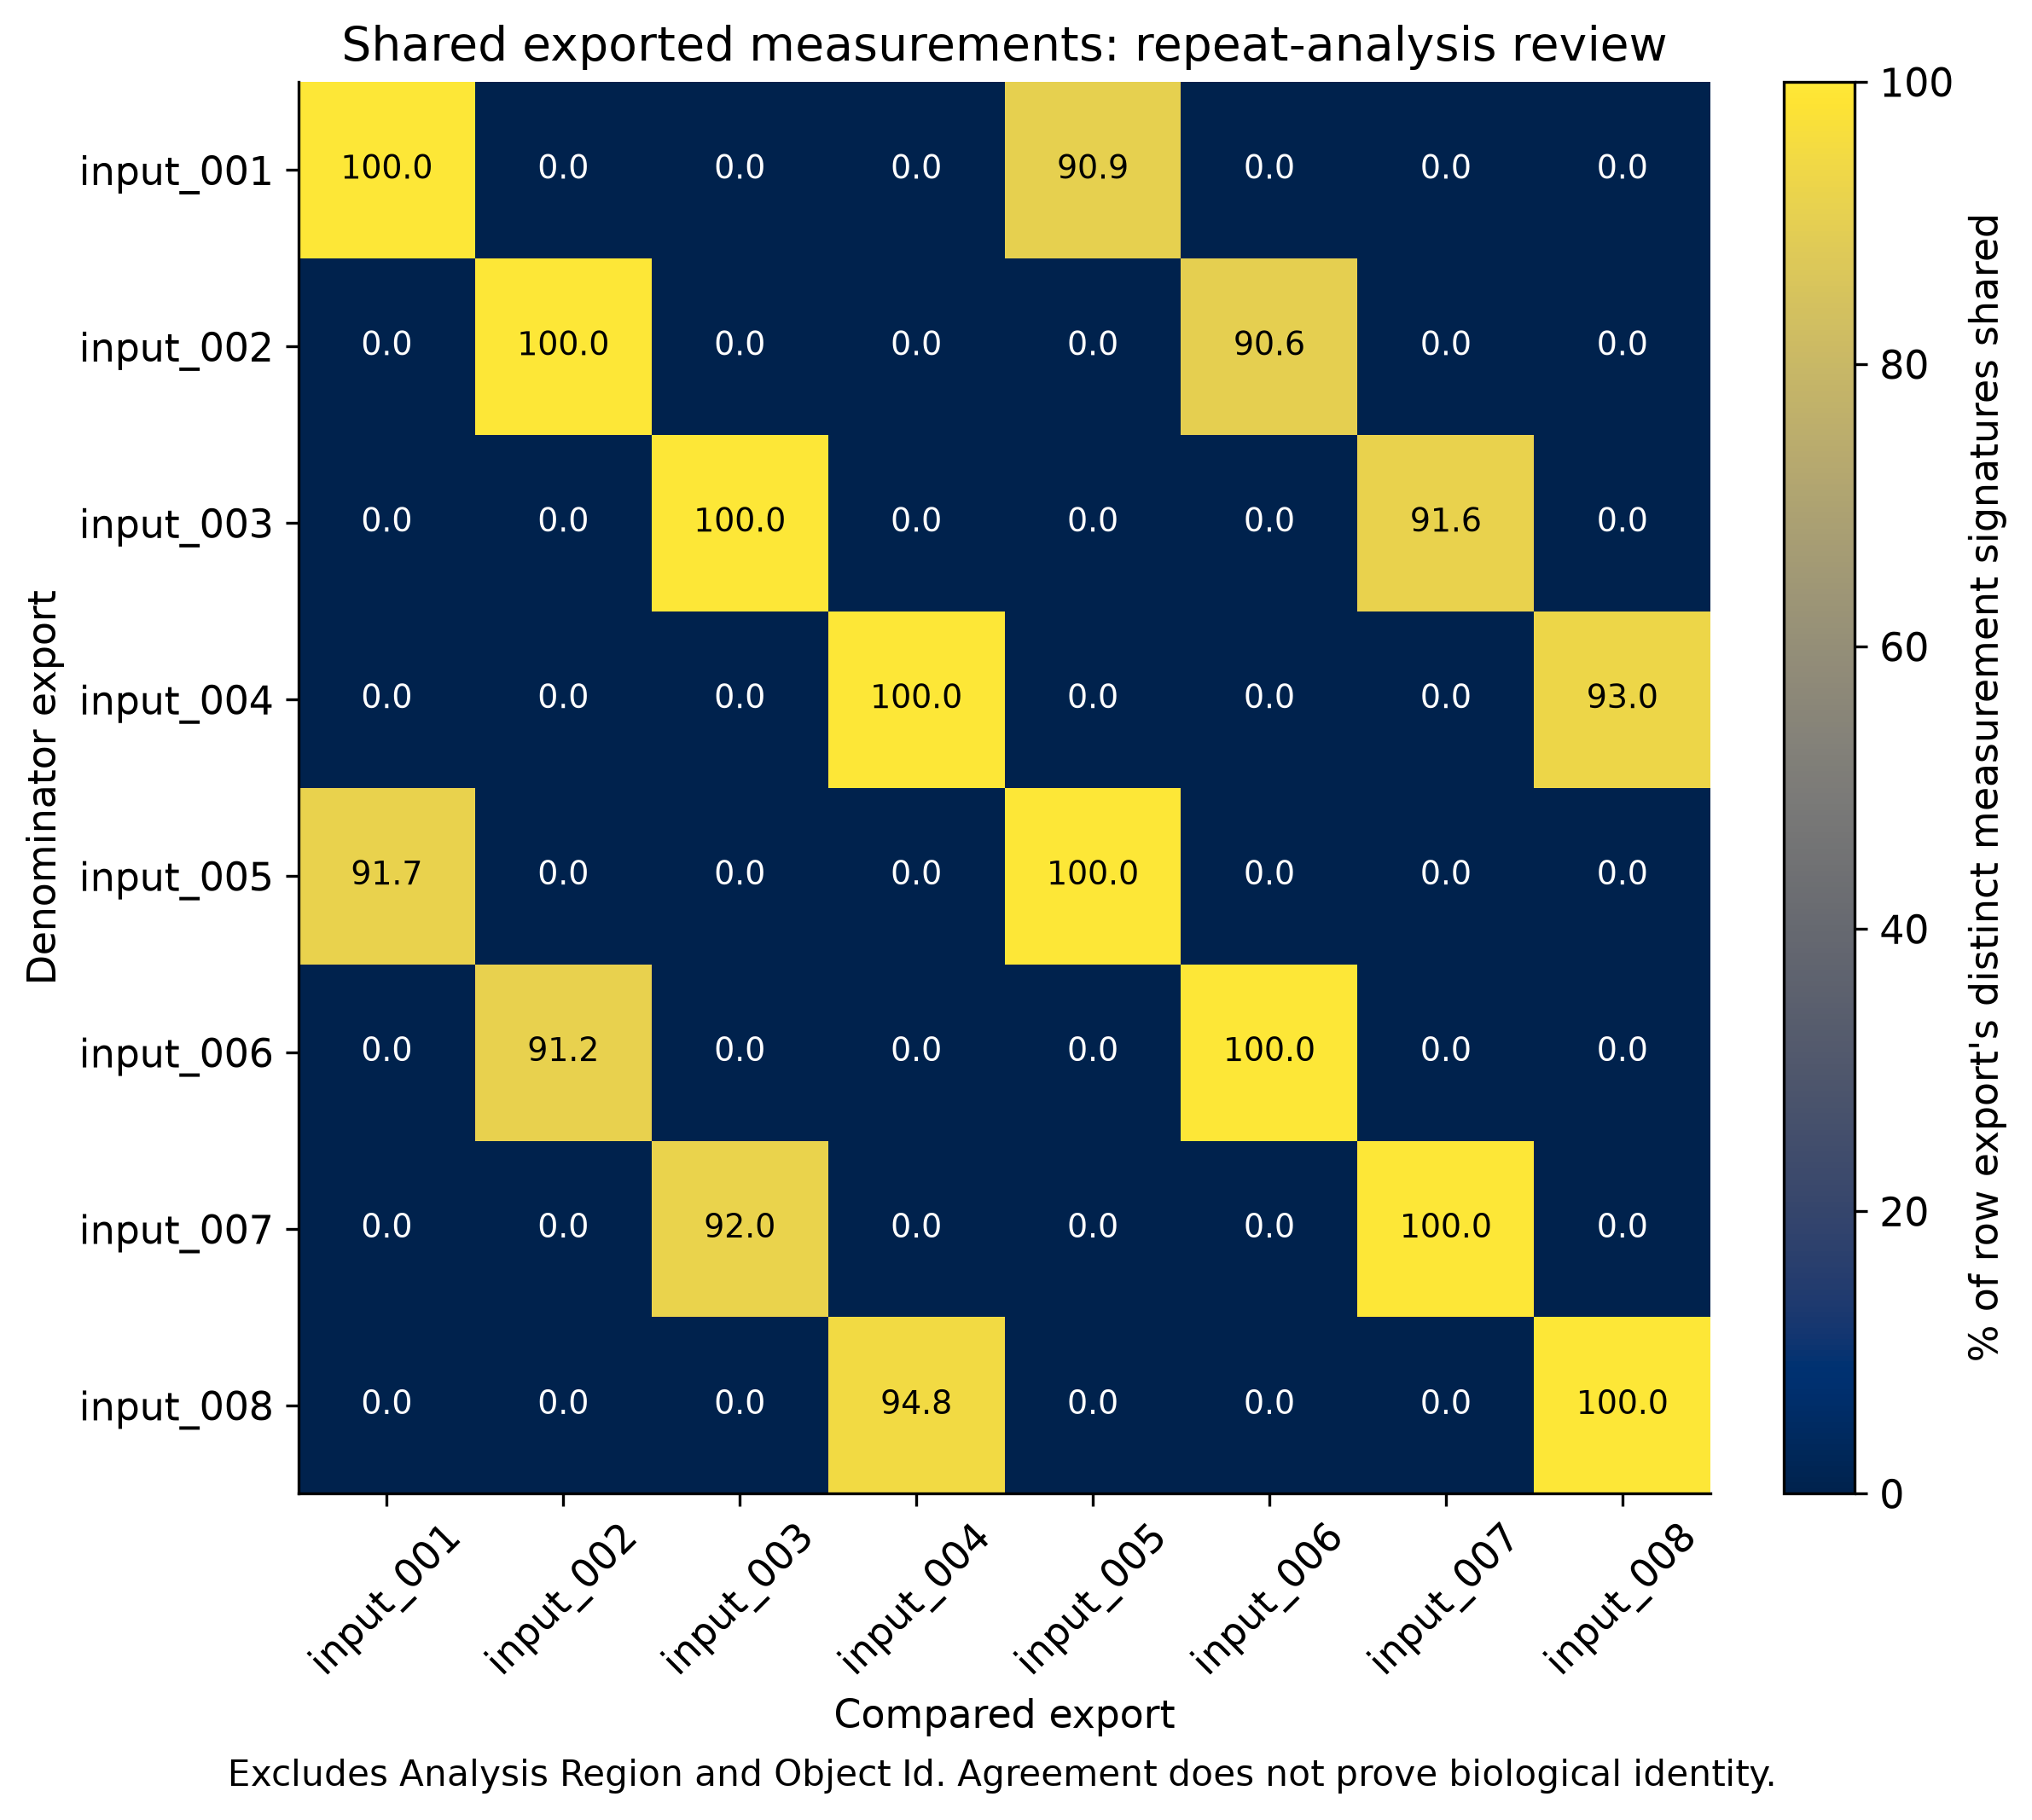

In [12]:
overlap = pd.read_csv(ROOT / 'outputs/inventory/within_input_overlap.csv')
columns = ['left_file_id','right_file_id','measurement_signatures_shared_excluding_region_and_object_id','left_signature_shared_fraction','right_signature_shared_fraction']
display(overlap.sort_values('measurement_signatures_shared_excluding_region_and_object_id', ascending=False)[columns].head(8))
display(Image(filename=str(ROOT / 'outputs/figures/input_measurement_overlap.png'), width=800))

**Reading the overlap figure:** entry (row, column) is the percentage of the row export's distinct measurement signatures also found in the column export. The signature includes all exported fields except Analysis Region and Object Id. The diagonal is 100% by definition; asymmetric values have different denominators. This is exact exported-value agreement, not validated biological object matching, and it ignores repeated identical-signature multiplicity.

**Supported finding:** four file pairs share approximately 91–95% of distinct measurement signatures. These are strong candidates for repeated/alternative analyses. **Uncertainty:** their intended sample/ROI relationship is not resolved by those numbers. **Next:** document inclusions and relationships; never concatenate them as new animals.

## Data dictionary and measurement limits

All 20 source fields are profiled, including missingness and numerical ranges. Header-labelled area/diameter units are preserved as export labels. They do not validate X/Y calibration. Bounding-box minima/maxima are present; no centroid-named field is present. Native exploratory maps explicitly reconstruct bounding-box midpoints. Whether that proxy is acceptable for the PDF's requested aligned-centroid calculation remains unresolved.

In [13]:
dictionary = pd.read_csv(ROOT / 'metadata/data_dictionary.csv', keep_default_na=False)
display(dictionary[['column','units_or_representation','observed_types','missing_count_all_files','limitations']])
scan_validation = json.loads((ROOT / 'outputs/inventory/validation.json').read_text())
assert scan_validation.get('status') == 'passed', 'Full input scan validation failed'
display(Markdown('**Full scan validation:**'))
display(scan_validation)

,column,units_or_representation,observed_types,missing_count_all_files,limitations
0,Image Location,path text,string,0,Path agreement alone does not establish acquis...
1,Analysis Region,label,string,0,May suggest a sample/marker label; requires sc...
2,Algorithm Name,label,string,0,Parameters and segmentation validation are not...
3,Object Id,identifier,integer_valued,0,Not a cross-export specimen/object corresponde...
4,Object Type,label,string,0,"A row is a detection, not an independent biolo..."
5,Area in PLA and Chat coloc,not explicitly stated in this header,numeric,0,Do not assign calibration from related column ...
6,% Area in PLA and Chat coloc,% (export header),numeric,0,Algorithm denominator must be confirmed; not t...
7,Area (µm²),µm² (export header; calibration unverified),numeric,0,Header units do not independently validate X/Y...
8,Inner Area (µm²),µm² (export header; calibration unverified),numeric,0,Header units do not independently validate X/Y...
9,Outer Area (µm²),µm² (export header; calibration unverified),numeric,0,Header units do not independently validate X/Y...


**Full scan validation:**

{'completed_utc': '2026-11-10T01:31:08.167220+00:00',
 'method_version': '1.1',
 'status': 'passed',
 'source_sha256_verified_before_and_after_csv_scan': True,
 'file_count': 8,
 'column_profile_count': 160,
 'profile_and_object_type_row_counts_reconcile': True,
 'failures': [],
 'scope': 'Input audit consistency only; does not validate biological assignments, spatial alignment, calibration or analysis readiness.'}

## Required spatial computation

For each PLA arm, bin b and condition c, let V(c,b) contain only sections whose **existing mask contains the complete bin area**. Count each accepted aligned centroid once, separately per section. A fully covered empty bin contributes **0**; absent or partly covered tissue contributes **nothing** to numerator or denominator (p. 1).

Mean(c,b) = sum of counts from valid sections / number of valid sections.

Difference(b) = Mean(Running,b) − Mean(Homecage,b).

Display a difference only if each condition has at least one valid section. Retain both contributing-section counts beside it. Keep all grid edges, axis directions and masks in the same documented aligned reference. Existing transformations are applied without fitting a new alignment. Mask holes and full raster cell footprints matter; bin-centre tests, convex hulls and object occupancy do not implement 100% coverage.

Both difference maps must share symmetric color limits around zero. Missing coverage must look different from zero difference. Preserve the actual grid without smoothing/interpolation/normalization (p. 2).

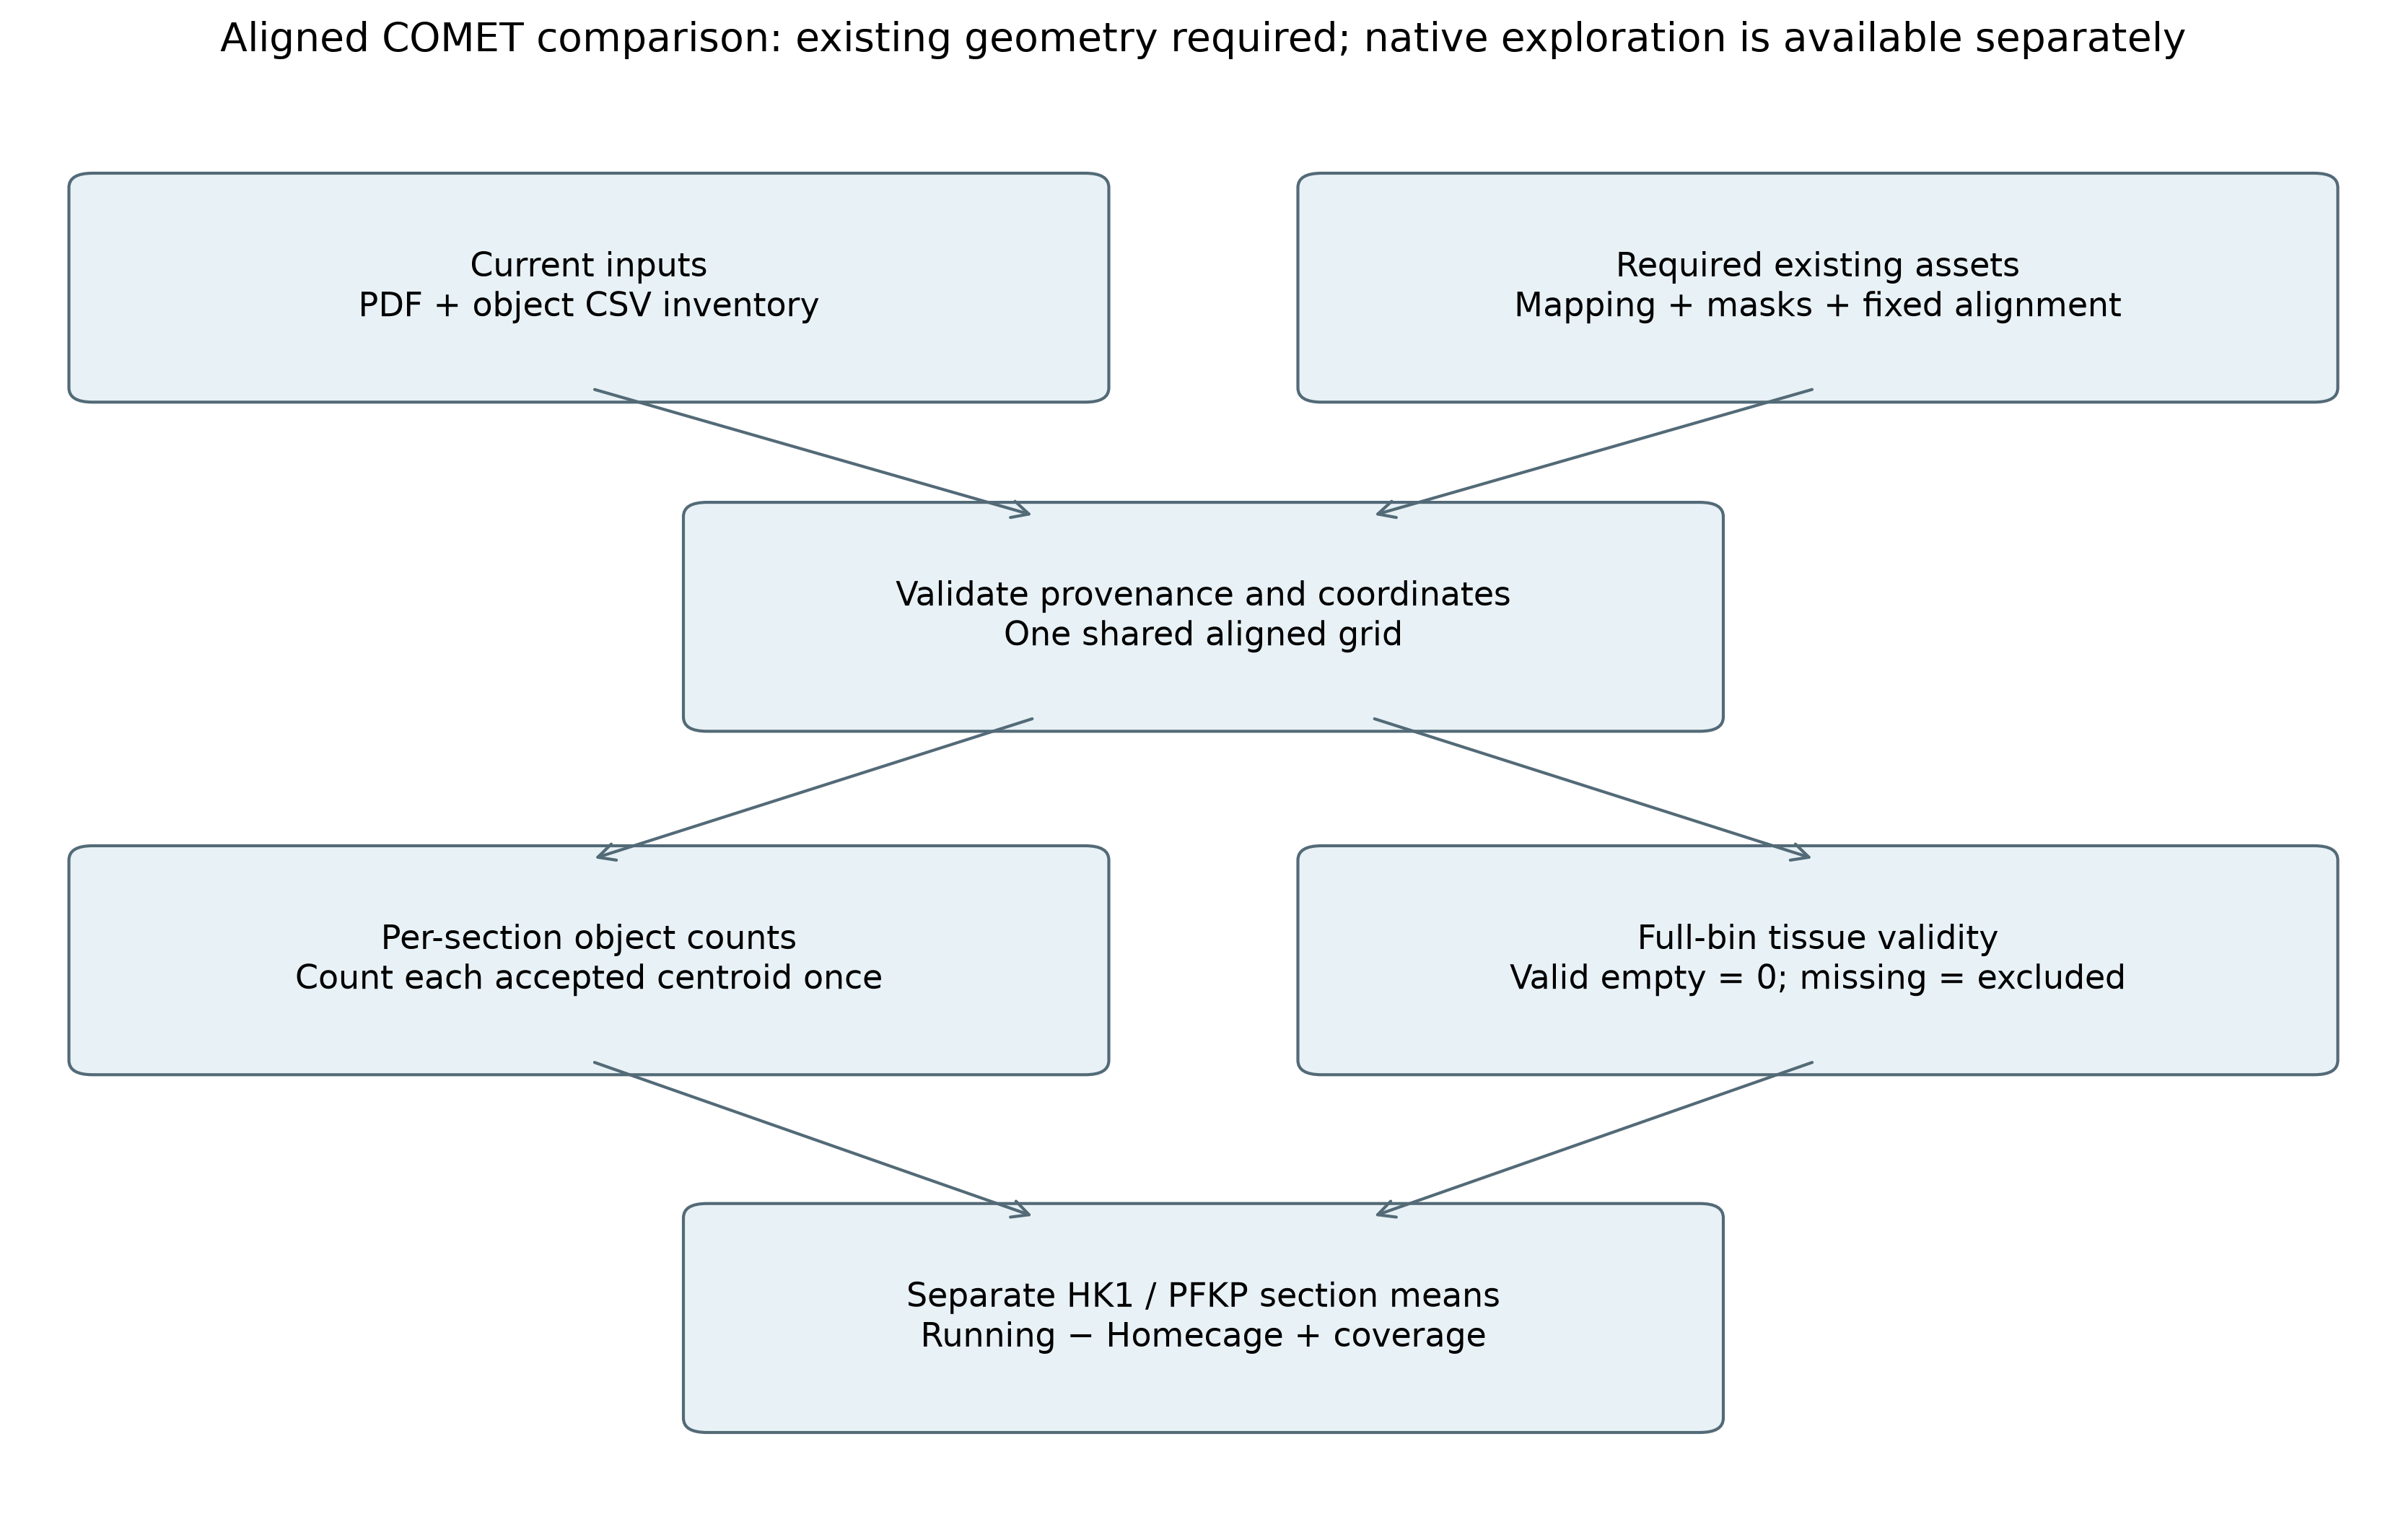

Spatial status: blocked


,unresolved_check
0,Confirmation missing: sample_relationships
1,confirmations.sample_relationships.evidence mu...
2,Confirmation missing: centroid_measurements
3,confirmations.centroid_measurements.evidence m...
4,Confirmation missing: existing_tissue_masks
5,confirmations.existing_tissue_masks.evidence m...
6,Confirmation missing: existing_fixed_alignment
7,confirmations.existing_fixed_alignment.evidenc...
8,Confirmation missing: duplicate_resolution
9,confirmations.duplicate_resolution.evidence mu...


In [14]:
display(Image(filename=str(ROOT / 'outputs/figures/workflow.png'), width=1000))
from comet_spatial.manifest import preflight_manifest
preflight = preflight_manifest(ROOT / 'metadata/analysis_manifest.json')
(ROOT / 'outputs/preflight.json').write_text(json.dumps(preflight, indent=2) + '\n')
print('Spatial status:', preflight['status'])
display(pd.DataFrame({'unresolved_check': preflight['blockers']}))
assert preflight['status'] == 'blocked', 'Manifest changed: run the spatial CLI and update the report with actual outputs before claiming results.'

## Software acceptance checks

The following tests use **synthetic software fixtures only**. They are not the new experiment and no synthetic heatmap is presented as a result. They verify valid empty bins, strict boundary/hole coverage, raster geometry, single bin assignment, fixed transforms, separate-arm averaging, missing coverage and input provenance. The PDF's arithmetic example (Homecage 3/5/4; Running 7/8/9) must yield +4 (p. 2). A passing software test does not approve anatomical alignment.

In [15]:
import contextlib, io, unittest
suite = unittest.defaultTestLoader.discover(str(ROOT / 'tests'), pattern='test_*.py')
log = io.StringIO()
with contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
    test_result = unittest.TextTestRunner(stream=log, verbosity=1).run(suite)
print(f'{test_result.testsRun} synthetic software checks; failures={len(test_result.failures)}, errors={len(test_result.errors)}')
if not test_result.wasSuccessful():
    print(log.getvalue())
(ROOT / 'outputs/test_log.txt').write_text(log.getvalue())
assert test_result.testsRun > 0 and test_result.wasSuccessful(), 'Acceptance tests failed'
validation = {'aligned_condition_analysis_status': preflight['status'], 'aligned_condition_maps_generated': False,
              'native_export_maps_generated': True, 'native_exports_computed': len(atlas['exports']),
              'input_hashes_verified': len(integrity), 'all_input_hashes_match': all(r['sha256_matches'] for r in integrity),
              'tests_run': test_result.testsRun, 'test_failures': len(test_result.failures), 'test_errors': len(test_result.errors),
              'scope': 'Full native object reconstructions and descriptive export measurements; historical results retained as context; no new aligned condition contrast.'}
(ROOT / 'outputs/validation.json').write_text(json.dumps(validation, indent=2) + '\n')
print(json.dumps(validation, indent=2))

58 synthetic software checks; failures=0, errors=0
{
  "aligned_condition_analysis_status": "blocked",
  "aligned_condition_maps_generated": false,
  "native_export_maps_generated": true,
  "native_exports_computed": 8,
  "input_hashes_verified": 8,
  "all_input_hashes_match": true,
  "tests_run": 58,
  "test_failures": 0,
  "test_errors": 0,
  "scope": "Full native object reconstructions and descriptive export measurements; historical results retained as context; no new aligned condition contrast."
}


## Historical reuse and verified scientific context

The full comparison in `docs/background_reuse.md` distinguishes remote main `4631e1517f85de2c4bfb59879bf44f406770a903` from local historical HEAD `f7fda4e36774b456c0e7b6df24f9666332198586`. Existing notebook/audit patterns, source hashing, standalone Plotly delivery and high-resolution exports are reusable. Historical ChAT fractions, morphology clusters, point-support maps, provisional feature alignment, animal assignments and thresholds are unsuitable substitutes for this new count-map contract.

Primary sources verified on 9 November 2026:

- [Söderberg et al., 2006, Nature Methods](https://www.nature.com/articles/nmeth947): PLA method context and assay specificity. Does not establish direct binding or calibrated molecule counts in these data.
- [Barone et al., 2026, Acta Neuropathologica](https://pubmed.ncbi.nlm.nih.gov/41838122/): TDP-43/HK1 disease-model mechanisms. Supplies motivation, not this study's result.
- [Manzo et al., 2019, eLife](https://elifesciences.org/articles/45114): functional glycolysis experiments in TDP-43 models. Does not establish mammalian PFKP interaction from spatial counts.
- [Navikas et al., 2024, Scientific Reports](https://www.nature.com/articles/s41598-024-55387-w): COMET spatial extraction workflow. Its masks and segmentation settings cannot be transferred here.

[Shapely covers](https://shapely.readthedocs.io/en/stable/reference/shapely.covers.html) supports the no-exterior-point full-bin test; [NumPy histogram2d](https://numpy.org/doc/stable/reference/generated/numpy.histogram2d.html) documents explicit-edge counts and axis conventions. See `docs/research_methods.md` for verified identifiers, applicability and limitations.

## Actionable next steps

1. Locate the existing accepted numerical transforms, reference figure and its plotting recipe; preserve their identities/hashes. The new PDF states that alignment is accepted, while the available older metadata have no approvals. Locate the intended assets rather than fitting or self-approving replacements.
2. Supply existing tissue masks with exact coordinate geometry, including raster cell edges if applicable. No masks are inferred from detections.
3. Complete current sample/ROI/repeated-export relationships from authoritative experimental records, keeping animal and section IDs distinct.
4. Document centroid definition, units, reference axes and common grid. If a midpoint proxy is intended, clarify it explicitly.
5. Run the preflight and spatial pipeline; compare the reproduced alignment check to its accepted reference and inspect source channels/segmentation before interpreting count differences.

The offline explorer at `outputs/app/index.html` helps inspect supplied exports. It does not rerun computation or fill missing scientific metadata. No original files were changed; no data were pushed or published.